# An Introduction to Gradient Descent: How Machines Learn by Walking Downhill

**Companion notebook for the Marketing Data Science article**
by Joe Domaleski, [Country Fried Creative](https://countryfriedcreative.com) | [blog.marketingdatascience.ai](https://blog.marketingdatascience.ai)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/joedom99/introduction-to-gradient-descent/blob/main/introduction_to_gradient_descent.ipynb)

---

## What this notebook does

Gradient descent is the algorithm that trains most machine learning models and nearly every neural network, including the ones behind large language models. The idea is simple. Start with a guess, find which direction makes the model less wrong, take a small step that way, and repeat.

I like the sport of orienteering, where you find your way across country with a map and a compass. The ground is rarely level, so reading the slope is half of the job. Gradient descent is like orienteering at night with no map. You can't see the terrain, but you can feel which way the ground falls under your feet, and that's enough to walk downhill.

This notebook builds the idea from the ground up, in four stages:

1. **A simulated piece of terrain, drawn as a topographic map.** It teaches the mechanics: slope, the gradient, the step rule, the learning rate, when to stop, and how a walk gets stuck in a low spot that isn't the lowest one.
2. **A straight line fit to marketing data.** A small online shop's daily ad spend and revenue create a "terrain" of their own, called a loss surface. Gradient descent walks down it and lands on the same line the textbook formula gives.
3. **Stochastic gradient descent, momentum, and Adam.** These are the versions used on large data sets and in neural networks.
4. **A small neural network and a budget decision.** The line can't follow the bend in the data, so a neural network takes over. No formula can train it, so gradient descent has to. The trained network then recommends a daily ad budget, and we see what an under-trained model costs.

Everything is written from scratch in NumPy so you can see each step. An optional last cell repeats the neural network in PyTorch, where gradient descent is a single line of code.

All data in this notebook is simulated with illustrative assumptions. A fixed random seed keeps the results reproducible. The numbers quoted in the text describe the default settings.

## 1. Setup

This notebook only uses libraries that come preinstalled in Google Colab: NumPy, pandas, Matplotlib, SciPy, and scikit-learn. The figures and table images are saved to `figures/` and `tables/` at 300 dpi. Each table is also saved as a CSV file.

In [1]:
import os
import time
import textwrap
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from scipy.optimize import minimize, fsolve
import sklearn
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

SEED = 42  # each part draws from its own generator seeded from this, so cells can be rerun safely

os.makedirs("figures", exist_ok=True)
os.makedirs("tables", exist_ok=True)
print("NumPy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__)

NumPy 2.5.3 | pandas 3.0.5 | scikit-learn 1.9.1


### Figure and table style

Figures use my company's Country Fried Creative color palette on a white background. The cell below tries to download the Lato font. If that fails, Matplotlib falls back to its default font and everything still works.

The colors mean the same thing in every chart. Navy is the terrain or the data. Orange is plain gradient descent. Teal and gold are the second and third things being compared. Green marks a reference answer, such as the lowest point or the textbook formula's result. Red marks a problem, such as overshooting or getting stuck.

The `render_table` helper turns a small table into an image you can drop straight into an article.

In [2]:
# Country Fried Creative brand palette
TEAL   = "#6db7ac"
ORANGE = "#f58235"
RED    = "#c02126"
NAVY   = "#212f3f"
GREEN  = "#198a53"
GOLD   = "#eec35b"
GRAY   = "#8a929b"
CARD   = "#f2f3f5"
ACCENTS = [TEAL, ORANGE, GOLD, RED, NAVY, GREEN]

def load_lato():
    base = "https://raw.githubusercontent.com/google/fonts/main/ofl/lato/"
    try:
        for style in ["Lato-Regular.ttf", "Lato-Bold.ttf"]:
            path = os.path.join("/tmp", style)
            if not os.path.exists(path):
                urllib.request.urlretrieve(base + style, path)
            font_manager.fontManager.addfont(path)
        return True
    except Exception as e:
        print("Could not load Lato, using the default font instead:", e)
        return False

HAS_LATO = load_lato()

plt.rcParams.update({
    "font.family": "Lato" if HAS_LATO else "DejaVu Sans",
    "font.size": 11,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
    "axes.edgecolor": NAVY,
    "axes.labelcolor": NAVY,
    "axes.titlecolor": NAVY,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e8eb",
    "grid.linewidth": 0.8,
    "xtick.color": NAVY,
    "ytick.color": NAVY,
    "legend.frameon": False,
    "text.parse_math": False,  # treat $ signs as plain text
    "figure.dpi": 110,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

def save(fig, name):
    path = os.path.join("figures", name)
    fig.savefig(path)
    print("Saved", path)

def dollars(x, pos=None):
    return f"-${abs(x):,.0f}" if x < 0 else f"${x:,.0f}"

def render_table(fname, title, subtitle, df, widths, fs=11.5):
    # Draw a DataFrame as a styled table image and save it to tables/.
    headers = list(df.columns)
    rows = df.astype(str).values.tolist()
    cw, lh = 0.0074 * fs, 0.0225 * fs
    px, py, gap, accent_w = 0.16, 0.14, 0.10, 0.09
    col_w = [w * cw + 2 * px for w in widths]
    W = sum(col_w) + accent_w
    wrap = lambda t, w: textwrap.wrap(str(t), w, break_on_hyphens=False) or [""]
    hl = [wrap(h, w) for h, w in zip(headers, widths)]
    bl = [[wrap(c, w) for c, w in zip(r, widths)] for r in rows]
    hh = max(map(len, hl)) * lh + 2 * py
    rh = [max(map(len, r)) * lh + 2 * py for r in bl]
    top = 1.15
    H = top + hh + gap + sum(rh) + gap * len(rows) + 0.1

    fig = plt.figure(figsize=(W + 0.4, H))
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(-0.2, W + 0.2); ax.set_ylim(H, 0); ax.axis("off")
    ax.text(W / 2, 0.38, title, fontsize=fs + 13, fontweight="bold", color=NAVY, ha="center", va="center")
    ax.text(W / 2, 0.86, subtitle, fontsize=fs + 2.5, color=GRAY, ha="center", va="center")

    y = top
    ax.add_patch(FancyBboxPatch((0, y), W, hh, boxstyle="round,pad=0,rounding_size=0.14", fc=NAVY, ec="none"))
    x = accent_w
    for lines, w in zip(hl, col_w):
        ax.text(x + px, y + hh / 2, "\n".join(lines), color="white", fontsize=fs + 1,
                fontweight="bold", va="center", linespacing=1.2)
        x += w
    y += hh + gap
    for i, (r, h) in enumerate(zip(bl, rh)):
        ax.add_patch(FancyBboxPatch((0, y), W, h, boxstyle="round,pad=0,rounding_size=0.14", fc=CARD, ec="none"))
        ax.add_patch(FancyBboxPatch((0, y), accent_w + 0.06, h, boxstyle="round,pad=0,rounding_size=0.06",
                                    fc=ACCENTS[i % len(ACCENTS)], ec="none"))
        ax.add_patch(plt.Rectangle((accent_w, y), 0.06, h, fc=CARD, ec="none"))
        x = accent_w
        for j, (lines, w) in enumerate(zip(r, col_w)):
            ax.text(x + px, y + py, "\n".join(lines), color=NAVY, fontsize=fs,
                    fontweight="bold" if j == 0 else "normal", va="top", linespacing=1.3)
            x += w
        y += h + gap
    path = os.path.join("tables", fname)
    fig.savefig(path, dpi=300, facecolor="white", bbox_inches=None)
    plt.close(fig)
    df.to_csv(path.replace(".png", ".csv"), index=False)  # selectable text version
    print("Saved", path, "and a CSV copy")

print("Font:", plt.rcParams["font.family"])

Font: ['Lato']


### Settings

All the assumptions live in the next cells, so you can change them in one place and rerun everything.

- **`T` (terrain)** describes the simulated landscape: a wide basin with one lowest point, a smaller depression partway up the slope, two hills, and where the walks start.
- **`A` (ad-spend data)** describes the simulated shop: how many days of history, how revenue responds to ad spend, and how noisy it is. Because the data is simulated, we know the true curve, which lets the notebook check how close each model gets.
- **`C` (costs)** holds the shop's gross margin, which turns a revenue curve into a budget decision.
- **`G` (gradient descent)** holds the learning rates, the stopping tolerance, and the step limit.
- **`B` (batches)** holds the settings for stochastic gradient descent.
- **`M` (momentum and Adam)** holds the settings for the two most common upgrades.
- **`N` (neural network)** holds the size of the network and how it's trained.

In [3]:
T = {
    "size_km": 10,                 # the map is a 10 km by 10 km square
    "low_point": (7.0, 3.2),       # center of the main basin (east km, north km)
    "basin_depth": 75,             # how far the basin drops below the surrounding upland, in meters
    "basin_radius": 5.0,           # how wide the basin is, in km
    # Smaller features: (height in meters, east km, north km, width in km). Negative height = a hollow.
    "features": [
        (-30, 2.9, 6.9, 1.0),      # a depression partway up the slope
        ( 30, 8.3, 8.3, 1.5),      # a broad hill in the northeast
        ( 22, 4.3, 2.0, 0.9),      # a small hill southwest of the basin
    ],
    "start_a": (1.0, 1.2),         # a start in the southwest
    "start_b": (0.8, 9.3),         # a start in the northwest, on flatter ground
    "contour_interval": 2,         # meters between contour lines
    "index_every": 5,              # every fifth contour is drawn heavier, as on a real map
}

In [4]:
A = {
    "n_days": 1000,                # days of history
    "spend_range": (20, 500),      # daily ad spend varied between these amounts, in dollars
    "revenue_ceiling": 1500,       # daily revenue levels off near this amount, in dollars
    "spend_scale": 180,            # how quickly returns diminish; smaller = revenue flattens sooner
    "revenue_noise": 60,           # day-to-day noise in revenue, in dollars
}

C = {
    "gross_margin": 0.50,          # share of revenue left after cost of goods
}
# Revenue the next ad dollar must bring back to pay for itself after cost of goods
BREAKEVEN = 1 / C["gross_margin"]
print(f"Breakeven: the next ad dollar must bring back ${BREAKEVEN:.2f} of revenue")

Breakeven: the next ad dollar must bring back $2.00 of revenue


In [5]:
G = {
    "tolerance": 1e-10,            # stop when the loss improves by less than this in one step
    "max_steps": 10000,            # safety limit on the number of steps
    # Terrain (elevation in meters, position in km)
    "terrain_rate": 0.03,          # a learning rate that works well on the terrain
    "terrain_rate_small": 0.002,   # too small: the walk crawls
    "terrain_rate_large": 0.28,    # too large: the walk overshoots
    "steps_shown": 60,             # steps drawn when comparing the three learning rates
    # A one-dimensional bowl, f(x) = x^2
    "bowl_start": 4.0,
    "bowl_rates": [0.1, 0.5, 0.95, 1.05],
    # The straight line fit to the ad-spend data
    "line_rate": 0.05,             # with ad spend measured in hundreds of dollars
    "line_rate_raw": 1e-5,         # with ad spend in raw dollars, anything much larger blows up
    "line_rate_standardized": 0.3, # with ad spend standardized
}

B = {
    "batch_sizes": [1, 32],        # single-row and mini-batch; full batch is always included
    "epochs": 50,                  # passes through the data
    "rate": 0.01,                  # the same learning rate for all three, so the comparison is fair
    "decay": 0.001,                # schedule: rate / (1 + decay * step)
    "n_seeds": 20,                 # repeat runs to see how much the answers vary
}

M = {
    "momentum": 0.9,               # share of the previous step that carries over
    "momentum_rate": 0.01,
    "adam_rate": 0.1,
    "adam_beta1": 0.9,             # the Adam paper's defaults
    "adam_beta2": 0.999,
    "adam_epsilon": 1e-8,
}

N = {
    "hidden_units": 8,             # one hidden layer
    "rate": 0.01,
    "batch_size": 32,
    "epochs": 1000,
    "snapshots": [0, 1, 10, 100, 1000],   # epochs at which to save the network
    "n_starts": 10,                # random starting points, to see how much the result varies
}

## 2. The terrain

To learn the mechanics, we need ground to walk on. The cell below builds a 10 km by 10 km landscape from a formula: a wide basin with one lowest point, a smaller depression partway up the slope, and two hills. Elevation is in meters.

I built it from a formula, not from random noise, for two reasons. I can place each feature on purpose, and I know the exact slope at every point, which lets the notebook check its own math later.

A topographic map shows elevation with **contour lines**. Every point on one line is at the same height. Lines packed close together mean steep ground. Lines far apart mean gentle ground. Every fifth line is drawn heavier and labeled with its elevation, as on a real map.

Lowest point (global minimum): [7.04 3.2 ] at 0.2 m
Bottom of the depression (local minimum): [3.18 6.64] at 21.1 m
Saddle between them: [4.11 5.77] at 26.3 m
Elevation on the map runs from 0 m to 84 m


Saved figures/fig01_topo_map.png


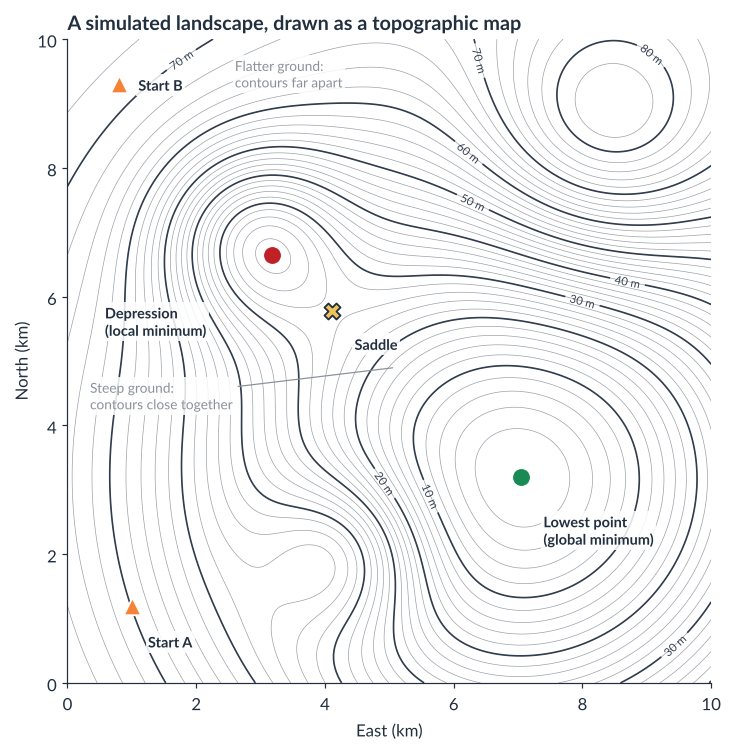

In [6]:
def elevation(p):
    # Height of the ground in meters at position p = (east km, north km). Works on one point or many.
    p = np.asarray(p, dtype=float)
    x, y = p[..., 0], p[..., 1]
    r2 = (x - T["low_point"][0]) ** 2 + (y - T["low_point"][1]) ** 2
    z = T["basin_depth"] * (1 - np.exp(-r2 / T["basin_radius"] ** 2))
    for h, cx, cy, w in T["features"]:
        z = z + h * np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * w ** 2))
    return z

def terrain_gradient(p):
    # The slope of the ground at p, worked out by hand with calculus: [slope going east, slope going north],
    # in meters of climb per km. Section 4 explains what this is.
    p = np.asarray(p, dtype=float)
    x, y = p[..., 0], p[..., 1]
    r2 = (x - T["low_point"][0]) ** 2 + (y - T["low_point"][1]) ** 2
    k = T["basin_depth"] * np.exp(-r2 / T["basin_radius"] ** 2) * 2 / T["basin_radius"] ** 2
    gx, gy = k * (x - T["low_point"][0]), k * (y - T["low_point"][1])
    for h, cx, cy, w in T["features"]:
        e = h * np.exp(-((x - cx) ** 2 + (y - cy) ** 2) / (2 * w ** 2))
        gx, gy = gx - e * (x - cx) / w ** 2, gy - e * (y - cy) / w ** 2
    return np.stack([gx, gy], axis=-1)

# Find the landmarks with standard solvers, so we have reference answers to compare against
LOW = minimize(elevation, T["low_point"]).x                      # the lowest point on the map
DEP = minimize(elevation, T["features"][0][1:3]).x               # the bottom of the depression
SADDLE = fsolve(terrain_gradient, (LOW + DEP) / 2 + [-0.9, 0.9]) # the pass between them
START_A, START_B = np.array(T["start_a"]), np.array(T["start_b"])

# A grid of elevations for drawing the map
_axis = np.linspace(0, T["size_km"], 301)
MAP_X, MAP_Y = np.meshgrid(_axis, _axis)
MAP_Z = elevation(np.stack([MAP_X, MAP_Y], axis=-1))

def draw_map(ax, labels=True, alpha=1.0, grid=(MAP_X, MAP_Y, MAP_Z)):
    # Draw the terrain as a topographic map: thin contour lines, with every fifth one heavier.
    X, Y, Z = grid
    step = T["contour_interval"]
    levels = np.arange(np.floor(Z.min() / step) * step, Z.max() + step, step)
    index = levels[np.isclose(levels % (step * T["index_every"]), 0)]
    ax.contour(X, Y, Z, levels=levels, colors=NAVY, linewidths=0.45, alpha=0.45 * alpha)
    cs = ax.contour(X, Y, Z, levels=index, colors=NAVY, linewidths=1.1, alpha=0.9 * alpha)
    if labels:
        ax.clabel(cs, fmt="%d m", fontsize=7.5, inline=True)
    ax.set_aspect("equal")
    ax.set_xlim(X.min(), X.max()); ax.set_ylim(Y.min(), Y.max())
    ax.grid(False)
    ax.set_xlabel("East (km)"); ax.set_ylabel("North (km)")

def mark(ax, p, kind, label=None, dx=0.25, dy=0.25, **kw):
    # Orienteering-style symbols: a triangle for a start, a circle for a low point
    style = {
        "start": dict(marker="^", s=130, fc=ORANGE, ec="white"),
        "low": dict(marker="o", s=150, fc=GREEN, ec="white"),
        "stuck": dict(marker="o", s=150, fc=RED, ec="white"),
        "saddle": dict(marker="X", s=110, fc=GOLD, ec=NAVY),
    }[kind]
    ax.scatter(p[0], p[1], marker=style["marker"], s=style["s"], facecolor=style["fc"],
               edgecolor=style["ec"], linewidth=1.2, zorder=6)
    if label:
        ax.annotate(label, (p[0], p[1]), xytext=(p[0] + dx, p[1] + dy), fontsize=9.5, color=NAVY, fontweight="bold",
                    zorder=7, bbox=dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.85), **kw)

print(f"Lowest point (global minimum): {LOW.round(2)} at {elevation(LOW):.1f} m")
print(f"Bottom of the depression (local minimum): {DEP.round(2)} at {elevation(DEP):.1f} m")
print(f"Saddle between them: {SADDLE.round(2)} at {elevation(SADDLE):.1f} m")
print(f"Elevation on the map runs from {MAP_Z.min():.0f} m to {MAP_Z.max():.0f} m")

fig, ax = plt.subplots(figsize=(7.6, 7.6))
draw_map(ax)
mark(ax, LOW, "low", "Lowest point\n(global minimum)", dx=0.35, dy=-1.05)
mark(ax, DEP, "stuck", "Depression\n(local minimum)", dx=-2.6, dy=-1.25)
mark(ax, SADDLE, "saddle", "Saddle", dx=0.35, dy=-0.6)
mark(ax, START_A, "start", "Start A", dx=0.25, dy=-0.65)
mark(ax, START_B, "start", "Start B", dx=0.3, dy=-0.1)
ax.annotate("Flatter ground:\ncontours far apart", (1.5, 8.9), xytext=(2.6, 9.25), fontsize=9, color=GRAY,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.85))
ax.annotate("Steep ground:\ncontours close together", (5.1, 4.9), xytext=(0.35, 4.25), fontsize=9, color=GRAY,
            bbox=dict(facecolor="white", edgecolor="none", pad=1.5, alpha=0.85),
            arrowprops=dict(arrowstyle="-", color=GRAY, lw=0.8))
ax.set_title("A simulated landscape, drawn as a topographic map")
save(fig, "fig01_topo_map.png")
plt.show()

Four places on this map matter for the rest of the notebook:

- **The lowest point**, at the bottom of the main basin. In machine learning terms this is the **global minimum**.
- **The depression**, a hollow partway up the slope to the northwest. Its floor is about 21 meters higher than the lowest point, but every direction out of it is uphill. This is a **local minimum**.
- **The saddle**, the pass between the depression and the basin. It's the low point of the ridge between them and the high point of the route through it.
- **The flatter ground** in the northwest corner, where the contour lines spread out.

Here's the translation to machine learning. A location on the map is one choice of a model's settings (its **parameters**, also called **weights**). The elevation is the **loss**, a number for how wrong the model is with those settings. The lowest point is the best model.

There's one big difference between an orienteer and a model. The orienteer has the map. A model doesn't. To draw this map I had to calculate the elevation at 90,000 points. A model with a million settings can't do the equivalent, so it works from the only thing it can measure: the slope where it stands.

## 3. Slope: the one idea from calculus you need

**Slope** is rise over run. A trail that climbs 10 meters over 100 meters of walking has a slope of 0.1. A curve has a different slope at every point, and the **derivative** is the slope at one point.

Calculus is the math of change, and it's used well beyond machine learning. Physics uses it for velocity and acceleration. Economics uses it every time the word "marginal" appears: marginal cost is the slope of the cost curve, and marginal revenue is the slope of the revenue curve. Marketers use the same idea when they ask what the next ad dollar brings back. We'll come back to that in Section 13.

You can estimate a slope with no calculus rules at all. Take a tiny step of size h and see how much the height changed:

```
slope at x  is about  (f(x + h) - f(x)) / h
```

For the simple curve f(x) = x^2, the rule from calculus says the slope at x is exactly 2x. The cell below compares the two.

   x  Step size h  Tiny-step estimate  Calculus rule (2x)
-2.0        1.000              -3.000                -4.0
-2.0        0.100              -3.900                -4.0
-2.0        0.001              -3.999                -4.0
 0.0        1.000               1.000                 0.0
 0.0        0.100               0.100                 0.0
 0.0        0.001               0.001                 0.0
 1.5        1.000               4.000                 3.0
 1.5        0.100               3.100                 3.0
 1.5        0.001               3.001                 3.0


Saved figures/fig02_slope_tangents.png


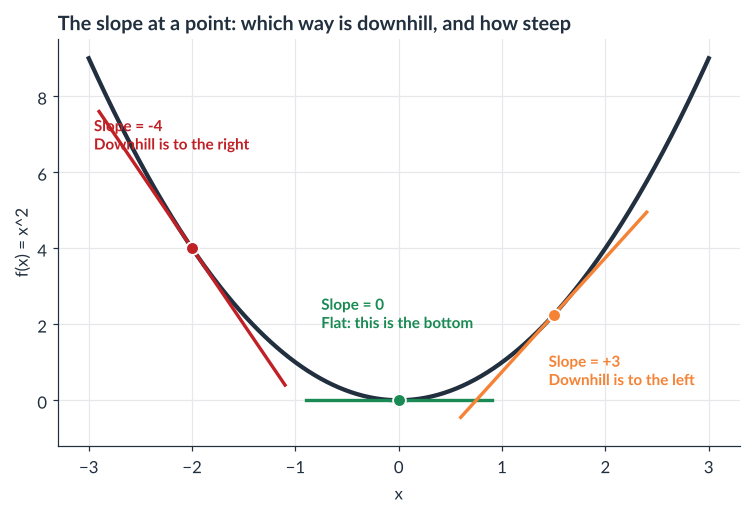

In [7]:
def bowl(x):
    return np.asarray(x, dtype=float) ** 2

def bowl_slope(x):
    return 2 * np.asarray(x, dtype=float)   # the calculus rule for x^2

rows = []
for x0 in [-2.0, 0.0, 1.5]:
    for h in [1.0, 0.1, 0.001]:
        rows.append({"x": x0, "Step size h": h, "Tiny-step estimate": (bowl(x0 + h) - bowl(x0)) / h,
                     "Calculus rule (2x)": float(bowl_slope(x0))})
slope_table = pd.DataFrame(rows)
print(slope_table.to_string(index=False))

xs = np.linspace(-3, 3, 301)
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(xs, bowl(xs), color=NAVY, lw=2.8)
notes = {-2.0: ("Slope = -4\nDownhill is to the right", RED, (-2.95, 6.6)),
         0.0: ("Slope = 0\nFlat: this is the bottom", GREEN, (-0.75, 1.9)),
         1.5: ("Slope = +3\nDownhill is to the left", ORANGE, (1.45, 0.4))}
for x0, (txt, col, pos) in notes.items():
    m, half = float(bowl_slope(x0)), 0.9
    tx = np.array([x0 - half, x0 + half])
    ax.plot(tx, bowl(x0) + m * (tx - x0), color=col, lw=2.2)
    ax.scatter([x0], [bowl(x0)], s=70, color=col, edgecolor="white", linewidth=1.2, zorder=5)
    ax.text(pos[0], pos[1], txt, color=col, fontsize=10, fontweight="bold")
ax.set_xlabel("x"); ax.set_ylabel("f(x) = x^2")
ax.set_ylim(-1.2, 9.5)
ax.set_title("The slope at a point: which way is downhill, and how steep")
save(fig, "fig02_slope_tangents.png")
plt.show()

The tiny-step estimate gets closer to the calculus rule as h shrinks. With h = 0.001 they agree to about three decimal places.

The slope tells you two things. Its **sign** says which way is downhill: a negative slope means the curve falls to the right, and a positive slope means it falls to the left. Its **size** says how steep the ground is. A slope of zero means you're on a flat spot, which might be the bottom.

## 4. From slope to gradient

A curve has one direction, so it has one slope. Terrain has two directions, so at every point it has two slopes: how fast the ground rises if you step east, and how fast it rises if you step north. Each one is a **partial derivative**, the slope in one direction with the other direction held still.

The **gradient** is those slopes written as a list:

```
gradient = [slope going east, slope going north]
```

On a map, the gradient is an arrow. It points in the steepest uphill direction, and its length is the steepness. Turn it around and you have what hikers and skiers call the **fall line**, the direction water would run. That reversed arrow is the **negative gradient**, and it's the direction gradient descent walks.

The chart below draws the uphill arrows across the map.

Saved figures/fig03_gradient_field.png


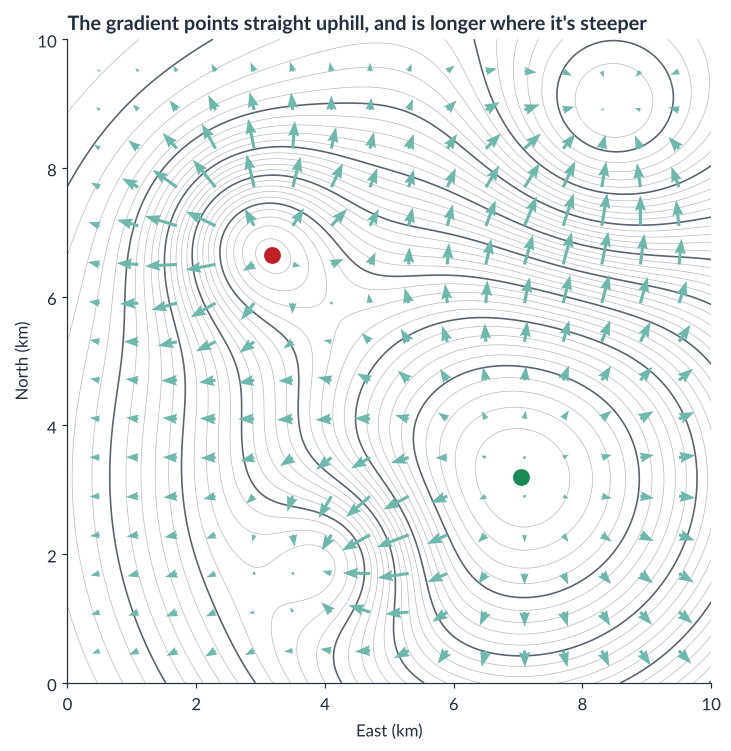

Hand-written gradient vs. tiny-step estimate: largest difference 1.7e-09 m per km
Slope measured a quarter turn from the gradient (along the contour): at most 1.4e-09 m per km
Steepness across the map: from 1.7 to 25.3 m per km


In [8]:
q_axis = np.linspace(0.5, 9.5, 16)
QX, QY = np.meshgrid(q_axis, q_axis)
QG = terrain_gradient(np.stack([QX, QY], axis=-1))
steepness = np.linalg.norm(QG, axis=-1)

fig, ax = plt.subplots(figsize=(7.6, 7.6))
draw_map(ax, labels=False, alpha=0.75)
ax.quiver(QX, QY, QG[..., 0], QG[..., 1], color=TEAL, angles="xy", scale_units="xy",
          scale=steepness.max() / 0.55, width=0.0048, headwidth=3.6, zorder=4)
mark(ax, LOW, "low"); mark(ax, DEP, "stuck")
ax.set_title("The gradient points straight uphill, and is longer where it's steeper")
save(fig, "fig03_gradient_field.png")
plt.show()

# Two quick checks of the claims above, at 20 random points
r_chk = np.random.default_rng(SEED)
pts = r_chk.uniform(0.5, 9.5, size=(20, 2))
h = 1e-5
fd = np.stack([(elevation(pts + [h, 0]) - elevation(pts - [h, 0])) / (2 * h),
               (elevation(pts + [0, h]) - elevation(pts - [0, h])) / (2 * h)], axis=-1)
GRAD_ERR = np.abs(fd - terrain_gradient(pts)).max()
g = terrain_gradient(pts)
along = np.stack([-g[:, 1], g[:, 0]], axis=-1) / np.linalg.norm(g, axis=-1, keepdims=True)  # a quarter turn from the gradient
ALONG_SLOPE = np.abs((elevation(pts + h * along) - elevation(pts - h * along)) / (2 * h)).max()
print(f"Hand-written gradient vs. tiny-step estimate: largest difference {GRAD_ERR:.1e} m per km")
print(f"Slope measured a quarter turn from the gradient (along the contour): at most {ALONG_SLOPE:.1e} m per km")
print(f"Steepness across the map: from {steepness.min():.1f} to {steepness.max():.1f} m per km")

Three things to notice:

- **The arrows cross the contour lines at right angles.** Walk along a contour and your height doesn't change, so the slope in that direction is zero. The steepest direction is a quarter turn away from it. The second check above confirms this: the slope measured a quarter turn from the gradient is zero to within rounding.
- **The arrows are long where the contours are packed together and short where they spread out.** In the flatter northwest corner they nearly vanish.
- **At the lowest point and at the bottom of the depression, the arrows shrink to nothing.** The gradient is zero at both. Remember that for Section 7.

The first check compares my hand-written gradient formula with the tiny-step estimate from Section 3, done in both directions. They agree, which is how I know the formula is right. The same check will be used on every gradient in this notebook, including the neural network's.

With more settings the list gets longer and the picture is gone, but the arithmetic doesn't change. A model with a million weights has a gradient with a million numbers, one slope per weight.

## 5. Gradient descent

Here's the whole algorithm:

```
new position = old position - learning rate * gradient
```

Find the slope where you stand, step the other way, and do it again. The **learning rate** sets how big a step to take for a given slope. The loop has four parts: start somewhere, compute the gradient, take a step, and decide whether to stop.

The `descend` function below is that loop. Every example in this notebook uses it. It also knows two upgrades, momentum and Adam, that we'll get to in Section 11.

From start A: 86 steps, converged = True
Ended at [7.043 3.197], elevation 0.16 m
Distance from the true lowest point: 0.0 m
Steps where the elevation went up: 0


Saved figures/fig04_descent_path.png


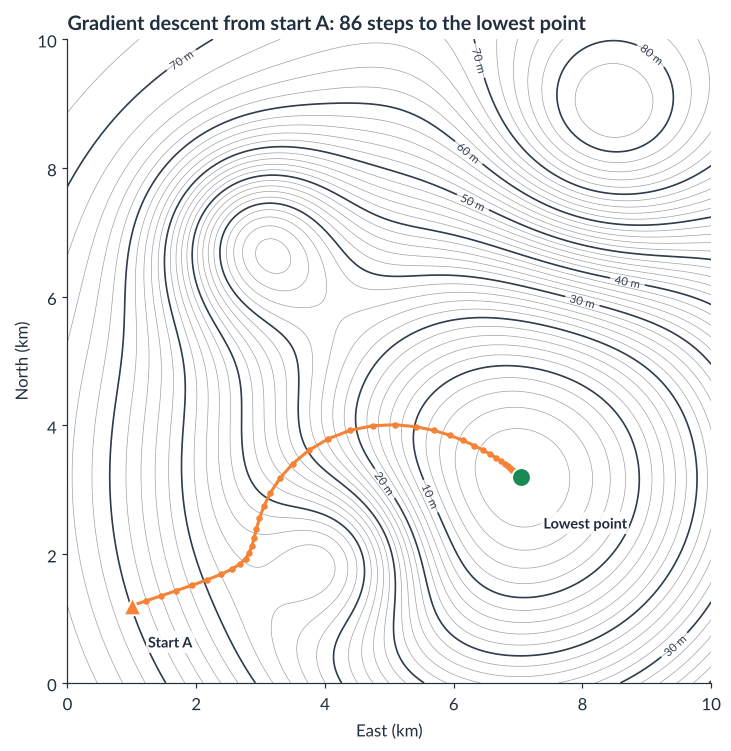

In [9]:
def descend(grad_fn, loss_fn, start, rate, max_steps=None, tol=None, optimizer="plain"):
    # Gradient descent. Returns the whole path so we can draw it.
    max_steps = G["max_steps"] if max_steps is None else max_steps
    tol = G["tolerance"] if tol is None else tol
    p = np.array(start, dtype=float)
    path, losses = [p.copy()], [float(loss_fn(p))]
    velocity = np.zeros_like(p)                    # used by momentum
    m, v = np.zeros_like(p), np.zeros_like(p)      # used by Adam
    converged = diverged = False
    for t in range(1, max_steps + 1):
        g = grad_fn(p)                             # 1. find the slope where we stand
        if optimizer == "plain":
            step = rate * g
        elif optimizer == "momentum":
            velocity = M["momentum"] * velocity + g
            step = rate * velocity
        elif optimizer == "adam":
            m = M["adam_beta1"] * m + (1 - M["adam_beta1"]) * g
            v = M["adam_beta2"] * v + (1 - M["adam_beta2"]) * g ** 2
            m_hat, v_hat = m / (1 - M["adam_beta1"] ** t), v / (1 - M["adam_beta2"] ** t)
            step = rate * m_hat / (np.sqrt(v_hat) + M["adam_epsilon"])
        else:
            raise ValueError("optimizer must be 'plain', 'momentum', or 'adam'")
        p = p - step                               # 2. step the other way
        loss = float(loss_fn(p))
        path.append(p.copy()); losses.append(loss)
        if not np.isfinite(loss) or abs(loss) > 1e15:
            diverged = True                        # the walk blew up
            break
        if abs(losses[-2] - losses[-1]) < tol:     # 3. stop when the loss has stopped improving
            converged = True
            break
    return {"path": np.array(path), "loss": np.array(losses), "steps": len(path) - 1,
            "converged": converged, "diverged": diverged}

walk_a = descend(terrain_gradient, elevation, START_A, G["terrain_rate"])
print(f"From start A: {walk_a['steps']} steps, converged = {walk_a['converged']}")
print(f"Ended at {walk_a['path'][-1].round(3)}, elevation {walk_a['loss'][-1]:.2f} m")
print(f"Distance from the true lowest point: {np.linalg.norm(walk_a['path'][-1] - LOW) * 1000:.1f} m")
ELEV_RISES_A = int((np.diff(walk_a["loss"]) > 1e-12).sum())
print(f"Steps where the elevation went up: {ELEV_RISES_A}")

fig, ax = plt.subplots(figsize=(7.6, 7.6))
draw_map(ax)
ax.plot(walk_a["path"][:, 0], walk_a["path"][:, 1], "-o", color=ORANGE, lw=2, ms=3.2, zorder=5)
mark(ax, START_A, "start", "Start A", dx=0.25, dy=-0.65)
mark(ax, LOW, "low", "Lowest point", dx=0.35, dy=-0.8)
ax.set_title(f"Gradient descent from start A: {walk_a['steps']} steps to the lowest point")
save(fig, "fig04_descent_path.png")
plt.show()

Each dot is one step. A few things are worth pointing out.

- **The path crosses every contour line at a right angle.** At each step the walk goes straight down the fall line, as Section 4 said it would.
- **It bends around the small hill.** Nothing planned that. The walk has no map and no route. It only follows the local slope, and the local slope leads around the hill.
- **The steps get shorter near the bottom.** Nobody told the algorithm to slow down. The step is the learning rate times the gradient, and the gradient shrinks as the ground flattens.
- **The elevation never went up.** With a sensible learning rate, every step is downhill.

This is also where the orienteering comparison stops. A real orienteer studies the map and chooses a clever route, maybe a longer one on a trail. Gradient descent has no route choice. It takes the locally steepest way down every time.

The method is old. The French mathematician Augustin-Louis Cauchy described it in 1847 as a way to solve equations from astronomy. More than a century later it became the engine of machine learning.

The next cell saves a plain version of this map, with no labels, for use as an article header image.

In [10]:
# A wide, label-free version of the map for a header image. The terrain formula works anywhere,
# so we can extend the map to the east and leave that side clear for a photo.
hx, hy = np.linspace(-1.0, 16.8, 500), np.linspace(-0.2, 9.8, 300)
HX, HY = np.meshgrid(hx, hy)
HZ = elevation(np.stack([HX, HY], axis=-1))
fig = plt.figure(figsize=(16, 9))
ax = fig.add_axes([0, 0, 1, 1])
draw_map(ax, labels=False, grid=(HX, HY, HZ))
ax.plot(walk_a["path"][:, 0], walk_a["path"][:, 1], "-", color=ORANGE, lw=5, zorder=5, solid_capstyle="round")
ax.scatter(*START_A, marker="^", s=700, facecolor=ORANGE, edgecolor="white", linewidth=2.5, zorder=6)
ax.scatter(*LOW, marker="o", s=700, facecolor=GREEN, edgecolor="white", linewidth=2.5, zorder=6)
fade = np.zeros((2, 256, 4)); fade[..., :3] = 1.0
fade[..., 3] = np.clip((np.linspace(0, 1, 256) - 0.12) / 0.5, 0, 1)   # white, fading in toward the right edge
ax.imshow(fade, extent=[hx.max() - 0.42 * (hx.max() - hx.min()), hx.max(), hy.min(), hy.max()],
          aspect="auto", zorder=8)
ax.set_xlim(hx.min(), hx.max()); ax.set_ylim(hy.min(), hy.max())
ax.set_aspect("auto"); ax.axis("off")
fig.savefig(os.path.join("figures", "hero_base.png"), dpi=200, bbox_inches=None)
plt.close(fig)
print("Saved figures/hero_base.png")

Saved figures/hero_base.png


## 6. Step size and knowing when to stop

### The learning rate

The learning rate is the main setting a person chooses, and it decides whether the method works. The chart below runs the same walk from start A three times with three learning rates, and gives each one the same 60 steps.

Saved figures/fig05_step_sizes.png


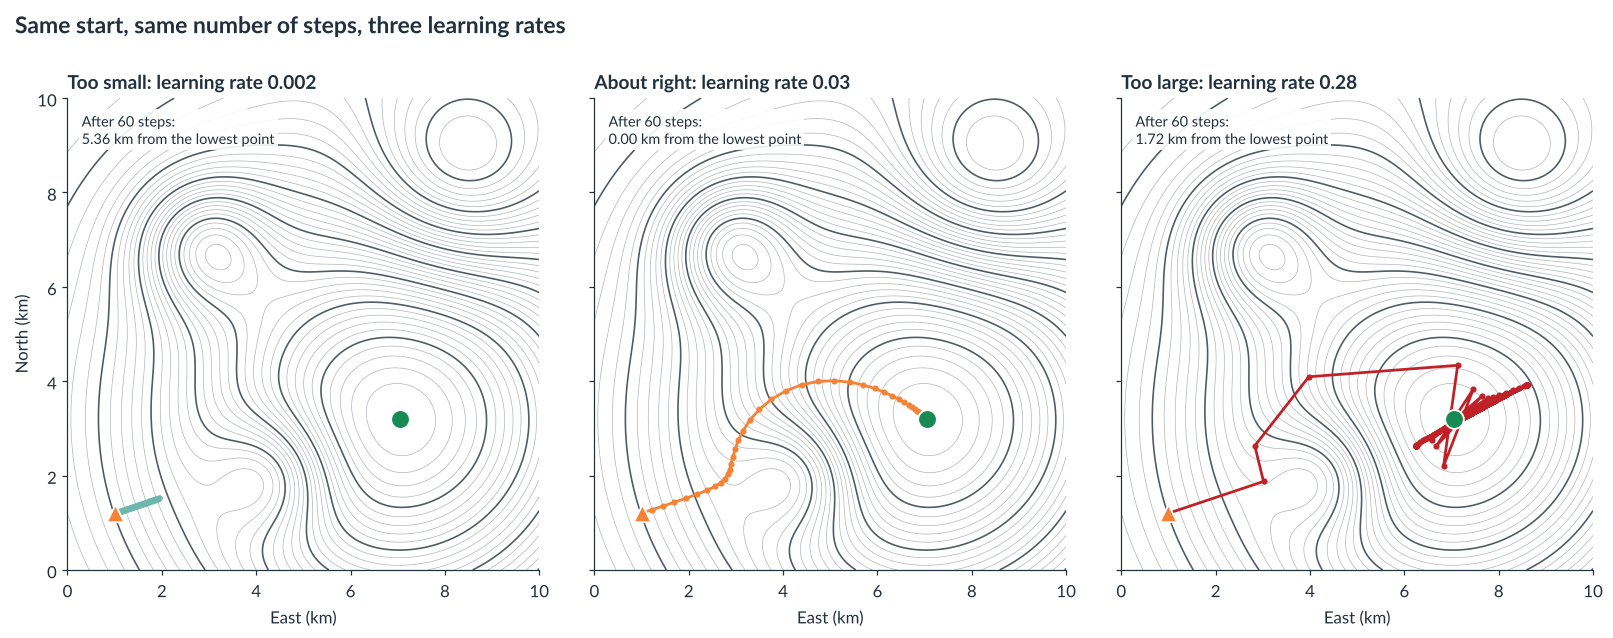

Too small    rate 0.002  after 60 steps: 5.36 km away, elevation 51.5 m, converged = False
About right  rate 0.03   after 60 steps: 0.00 km away, elevation 0.2 m, converged = False
Too large    rate 0.28   after 60 steps: 1.72 km away, elevation 9.2 m, converged = False


In [11]:
trio = [("Too small", G["terrain_rate_small"], TEAL),
        ("About right", G["terrain_rate"], ORANGE),
        ("Too large", G["terrain_rate_large"], RED)]
rate_walks = {name: descend(terrain_gradient, elevation, START_A, r, max_steps=G["steps_shown"]) for name, r, _ in trio}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.4), sharey=True)
for ax, (name, r, col) in zip(axes, trio):
    w = rate_walks[name]
    draw_map(ax, labels=False, alpha=0.8)
    ax.plot(w["path"][:, 0], w["path"][:, 1], "-o", color=col, lw=1.8, ms=3, zorder=5)
    mark(ax, START_A, "start"); mark(ax, LOW, "low")
    left = np.linalg.norm(w["path"][-1] - LOW)
    ax.set_title(f"{name}: learning rate {r}", fontsize=12.5)
    ax.text(0.03, 0.97, f"After {w['steps']} steps:\n{left:.2f} km from the lowest point",
            transform=ax.transAxes, va="top", fontsize=9.5, color=NAVY,
            bbox=dict(facecolor="white", edgecolor="none", pad=2, alpha=0.9))
    if ax is not axes[0]:
        ax.set_ylabel("")
fig.suptitle("Same start, same number of steps, three learning rates", x=0.02, y=1.0, ha="left",
             fontsize=15, fontweight="bold", color=NAVY)
fig.tight_layout(rect=[0, 0, 1, 0.96])
save(fig, "fig05_step_sizes.png")
plt.show()
for name, r, _ in trio:
    w = rate_walks[name]
    print(f"{name:12s} rate {r:<6} after {w['steps']} steps: {np.linalg.norm(w['path'][-1] - LOW):.2f} km away, "
          f"elevation {w['loss'][-1]:.1f} m, converged = {w['converged']}")

With the small learning rate, the walk is heading the right way and has barely left the start. With the large one, it charges into the basin, runs past the lowest point, turns around, and runs past it again. In orienteering terms it keeps overrunning the control.

The simple curve from Section 3 shows exactly where "too large" begins. For f(x) = x^2 the slope is 2x, so one step of gradient descent does this:

```
new x = x - rate * 2x = (1 - 2 * rate) * x
```

Every step multiplies the distance from the bottom by the same number, (1 - 2 * rate). If that number is between -1 and 1, the walk closes in. If it's beyond -1, each step lands farther away than the last.

In [12]:
rows, bowl_runs = [], {}
for r in G["bowl_rates"]:
    xs_path = [G["bowl_start"]]
    for _ in range(20):
        xs_path.append(xs_path[-1] - r * float(bowl_slope(xs_path[-1])))
    bowl_runs[r] = np.array(xs_path)
    factor = 1 - 2 * r
    outcome = ("Lands on the bottom in one step" if abs(factor) < 1e-12 else
               "Closes in steadily" if 0 < factor < 1 else
               "Overshoots each time, but closes in" if -1 < factor < 0 else
               "Overshoots farther each time")
    rows.append({"Learning rate": r, "Each step multiplies the distance by": round(factor, 2),
                 "x after 1 step": round(xs_path[1], 3), "x after 20 steps": round(xs_path[20], 3), "What happens": outcome})
bowl_table = pd.DataFrame(rows)
print(f"Start at x = {G['bowl_start']}; the bottom is at x = 0")
print(bowl_table.to_string(index=False))

Start at x = 4.0; the bottom is at x = 0
 Learning rate  Each step multiplies the distance by  x after 1 step  x after 20 steps                        What happens
          0.10                                   0.8             3.2             0.046                  Closes in steadily
          0.50                                   0.0             0.0             0.000     Lands on the bottom in one step
          0.95                                  -0.9            -3.6             0.486 Overshoots each time, but closes in
          1.05                                  -1.1            -4.4            26.910        Overshoots farther each time


At 0.1 the walk closes in steadily. At 0.5 it lands on the bottom in a single step, which only happens because this curve is a perfect bowl. At 0.95 it jumps from side to side and still closes in. At 1.05 every jump lands farther out, and after 20 steps it's more than six times as far from the bottom as where it started. The cutoff for this curve is exactly 1.0.

Real loss surfaces don't come with a formula for the cutoff, but the behavior is the same. A learning rate that's too high shows up as a loss that bounces or climbs. One that's too low shows up as a loss that's still creeping down when you run out of patience.

### Knowing when to stop

An orienteer punches the control and knows the leg is done. A model has no flag to find, so it needs a rule. Three are common:

- **The gradient is close to zero.** The ground is flat, so there's nowhere left to go.
- **The loss stopped improving.** The last step lowered the loss by less than some small tolerance.
- **A step limit was reached.** This one is a safety net. Hitting it means the model ran out of steps before it finished.

**Convergence** means further steps no longer change the answer by an amount you care about. The cell below shows how many steps each rule takes on the walk from start A.

In [13]:
grad_size = np.linalg.norm(terrain_gradient(walk_a["path"]), axis=-1)
drop = -np.diff(walk_a["loss"])
dist_m = np.linalg.norm(walk_a["path"] - LOW, axis=-1) * 1000
def first_step(mask):
    return int(np.argmax(mask)) if mask.any() else None
stop_rows = []
for label, step in [("Gradient below 1 m per km", first_step(grad_size < 1.0)),
                    ("Gradient below 0.01 m per km", first_step(grad_size < 0.01)),
                    ("Loss improved by less than 0.001 m", first_step(drop < 1e-3) + 1),
                    (f"Loss improved by less than {G['tolerance']:g} m (the default here)", walk_a["steps"])]:
    stop_rows.append({"Stopping rule": label, "Steps": step, "Distance from the lowest point (m)": round(dist_m[step], 2)})
limited = descend(terrain_gradient, elevation, START_A, G["terrain_rate_small"], max_steps=200)
stop_rows.append({"Stopping rule": f"Step limit of 200 with the too-small rate ({G['terrain_rate_small']})", "Steps": limited["steps"],
                  "Distance from the lowest point (m)": round(np.linalg.norm(limited["path"][-1] - LOW) * 1000, 2)})
stop_table = pd.DataFrame(stop_rows)
print(stop_table.to_string(index=False))
print("\nThe last run did not converge:", not limited["converged"])

                                        Stopping rule  Steps  Distance from the lowest point (m)
                            Gradient below 1 m per km     37                              143.09
                         Gradient below 0.01 m per km     60                                1.38
                   Loss improved by less than 0.001 m     46                               23.14
Loss improved by less than 1e-10 m (the default here)     86                                0.01
    Step limit of 200 with the too-small rate (0.002)    200                             4150.01

The last run did not converge: True


A loose rule stops early and leaves you some distance from the bottom. A tight rule costs more steps to get closer. How close is close enough is a practical choice. If you only need to find the right valley, a loose rule is fine. If someone is going to quote the answer to two decimal places, it isn't.

The last row is the one to watch for in practice. The walk hit its step limit while it was still kilometers from the lowest point, and it still returned an answer. Most libraries print a warning when this happens. It's worth reading.

## 7. Getting stuck: local and global minimums

So far every walk started at A. The next one starts at B, in the northwest.

From start B: 23 steps, converged = True
Ended at [3.182 6.641], elevation 21.10 m
Distance from the depression floor: 0.0 m
Gradient where it stopped: 1.8e-05 m per km
Start A finished at 0.2 m. Start B finished at 21.1 m, 20.9 m higher.



Of 40,000 starting points: 73% reach the lowest point, 27% end in the depression, 0.0% end somewhere else


Saved figures/fig06_stuck.png


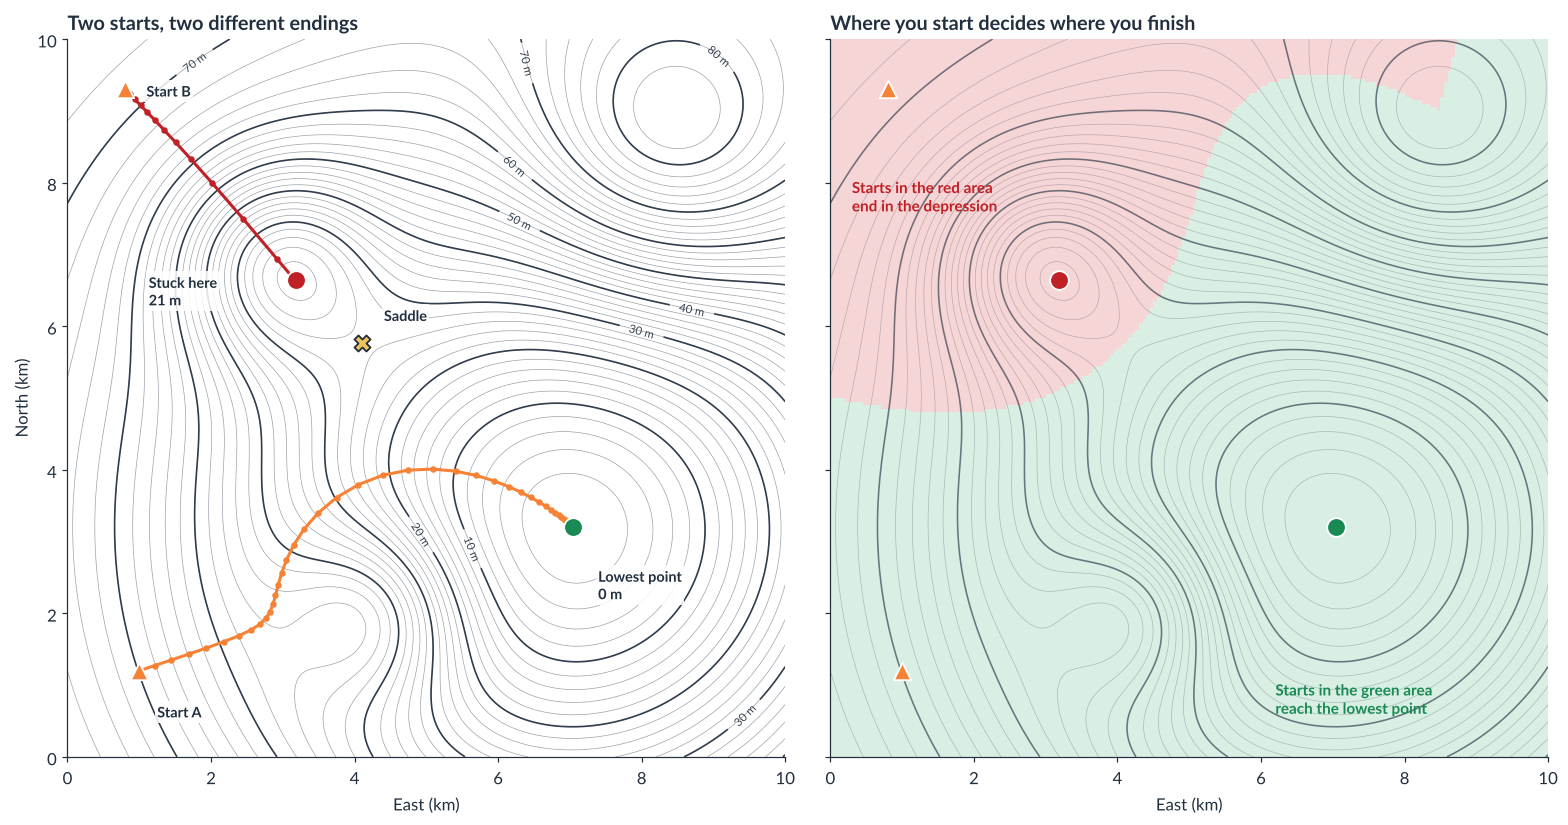

In [14]:
walk_b = descend(terrain_gradient, elevation, START_B, G["terrain_rate"])
print(f"From start B: {walk_b['steps']} steps, converged = {walk_b['converged']}")
print(f"Ended at {walk_b['path'][-1].round(3)}, elevation {walk_b['loss'][-1]:.2f} m")
print(f"Distance from the depression floor: {np.linalg.norm(walk_b['path'][-1] - DEP) * 1000:.1f} m")
print(f"Gradient where it stopped: {np.linalg.norm(terrain_gradient(walk_b['path'][-1])):.1e} m per km")
print(f"Start A finished at {walk_a['loss'][-1]:.1f} m. Start B finished at {walk_b['loss'][-1]:.1f} m, "
      f"{walk_b['loss'][-1] - walk_a['loss'][-1]:.1f} m higher.")

# Where does a walk end up from every possible start? Run gradient descent from a grid of starts, all at once.
b_axis = np.linspace(0.025, T["size_km"] - 0.025, 200)
BX, BY = np.meshgrid(b_axis, b_axis)
pos = np.stack([BX, BY], axis=-1)
for _ in range(4000):
    pos = pos - G["terrain_rate"] * terrain_gradient(pos)
ends_low = np.linalg.norm(pos - LOW, axis=-1) < 0.05
ends_dep = np.linalg.norm(pos - DEP, axis=-1) < 0.05
basin = np.where(ends_low, 0, np.where(ends_dep, 1, 2))
SHARE_STUCK = ends_dep.mean()
print(f"\nOf {basin.size:,} starting points: {ends_low.mean():.0%} reach the lowest point, "
      f"{SHARE_STUCK:.0%} end in the depression, {(basin == 2).mean():.1%} end somewhere else")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 7.2), sharey=True)
ax = axes[0]
draw_map(ax)
for w, col in [(walk_a, ORANGE), (walk_b, RED)]:
    ax.plot(w["path"][:, 0], w["path"][:, 1], "-o", color=col, lw=2, ms=3.2, zorder=5)
mark(ax, START_A, "start", "Start A", dx=0.25, dy=-0.65)
mark(ax, START_B, "start", "Start B", dx=0.3, dy=-0.1)
mark(ax, LOW, "low", f"Lowest point\n{elevation(LOW):.0f} m", dx=0.35, dy=-1.0)
mark(ax, DEP, "stuck", f"Stuck here\n{elevation(DEP):.0f} m", dx=-2.05, dy=-0.35)
mark(ax, SADDLE, "saddle", "Saddle", dx=0.3, dy=0.3)
ax.set_title("Two starts, two different endings")
ax = axes[1]
ax.pcolormesh(BX, BY, basin, cmap=ListedColormap(["#d9efe4", "#f6d5d6", "#eeeeee"]), vmin=0, vmax=2, shading="nearest")
draw_map(ax, labels=False, alpha=0.6)
mark(ax, LOW, "low"); mark(ax, DEP, "stuck"); mark(ax, START_A, "start"); mark(ax, START_B, "start")
ax.text(6.2, 0.6, "Starts in the green area\nreach the lowest point", fontsize=10, color=GREEN, fontweight="bold")
ax.text(0.3, 7.6, "Starts in the red area\nend in the depression", fontsize=10, color=RED, fontweight="bold")
ax.set_ylabel("")
ax.set_title("Where you start decides where you finish")
fig.tight_layout()
save(fig, "fig06_stuck.png")
plt.show()

The walk from start B went downhill at every step, just like the walk from A. It ended in the depression, about 21 meters above the lowest point on the map, and stopped there.

Picture it on a night course. You walk downhill into a hollow, and then every direction is uphill. By feel alone, you'd swear you had reached the lowest ground on the map. Gradient descent has the same blind spot. It stops wherever the gradient is zero, and the gradient is zero at the bottom of the depression just as it is at the bottom of the basin. The algorithm can't tell the two apart.

The right-hand map shows it isn't a fluke of one starting point. From about one start in four, a walk ends in the depression.

Some vocabulary:

- The lowest point on the whole map is the **global minimum**.
- A spot that's lower than everything around it, but not the lowest overall, is a **local minimum**.
- A **saddle** is level at its center, so a walk that arrives there slows to a crawl before drifting off to one side.
- On a **plateau**, the ground is nearly flat, the gradient is tiny, and so are the steps. The walk from B starts on flatter ground, which is why its first few dots are close together.

This is one reason a machine learning model can turn out worse than it should. Its training settled into a low spot and stopped. Train the same model again from a different random starting point and you may get a different, better one.

The same is true of the neural networks behind large language models, which are trained with a variant of gradient descent. Three details keep that statement accurate:

- **It happens during training, not while you chat.** Gradient descent runs when the model is built. If a chatbot repeats itself or goes in circles during a conversation, no gradient descent is running, and that's a different problem.
- **Nobody finds the global minimum for a model that large.** Training ends at a low spot that's good enough.
- **In very large networks, flat ground is the more common trouble.** Research suggests saddles and plateaus stall training more often than deep, bad depressions do, and that most low spots found in practice perform about equally well (Goodfellow et al., chapter 8). In small models like the ones in this notebook, a bad local minimum is a real and common trap.

Practitioners have three standard responses: start from several random points and keep the best result, add momentum (Section 11), and use the built-in randomness of stochastic gradient descent (Section 10) to shake the walk loose.

A surface with a single low point and no depressions is called **convex**. On a convex surface every start reaches the same answer. The next example is convex. The neural network in Section 12 is not.

## 8. From terrain to data: fitting a line

In machine learning, nobody hands you terrain. A model, a data set, and a loss function create it. Each choice of the model's settings gives a loss, and that loss is the elevation.

The example for the rest of the notebook is a small online shop. It has 1,000 days of history, and on each day it spent somewhere between \$20 and \$500 on ads. More spend brings more revenue, with diminishing returns: the first \$100 a day does much more than the fifth.

In [15]:
r_data = np.random.default_rng(SEED)
spend = r_data.uniform(*A["spend_range"], A["n_days"])

def true_revenue(s):
    # The curve the data is simulated from. A real shop never gets to see this.
    return A["revenue_ceiling"] * (1 - np.exp(-np.asarray(s, dtype=float) / A["spend_scale"]))

def true_revenue_slope(s):
    # Its derivative: the revenue the next ad dollar brings back at spend level s
    return A["revenue_ceiling"] / A["spend_scale"] * np.exp(-np.asarray(s, dtype=float) / A["spend_scale"])

revenue = true_revenue(spend) + r_data.normal(0, A["revenue_noise"], A["n_days"])
print(f"{A['n_days']:,} simulated days | ad spend ${spend.min():,.0f} to ${spend.max():,.0f} a day, "
      f"average ${spend.mean():,.0f} | revenue average ${revenue.mean():,.0f} a day")

1,000 simulated days | ad spend $21 to $500 a day, average $259 | revenue average $1,021 a day


Let's start with the simplest model, a straight line:

```
predicted revenue = intercept + rate * ad spend
```

It has two settings, the intercept and the rate. To score a pair of settings, I'll use **squared error**: take each day's miss, square it, and average. (My article on loss functions covers why you might choose something else.) Working out the slope of that loss with respect to each setting gives:

```
error               = predicted revenue - actual revenue
loss                = average of error^2
slope for intercept = 2 * average(error)
slope for rate      = 2 * average(error * ad spend)
```

Those two slopes are the gradient. I'll measure ad spend in hundreds of dollars here, so the rate reads as "revenue per extra \$100 of ad spend." Section 9 explains why the units matter.

Gradient descent: 713 steps, converged = True
  intercept $406.48, rate $237.71 per extra $100 of ad spend
Textbook formula:
  intercept $406.48, rate $237.71 per extra $100 of ad spend
Largest difference: $0.0001
Typical miss (RMSE): $125.76 a day


Saved figures/fig07_line_fit.png


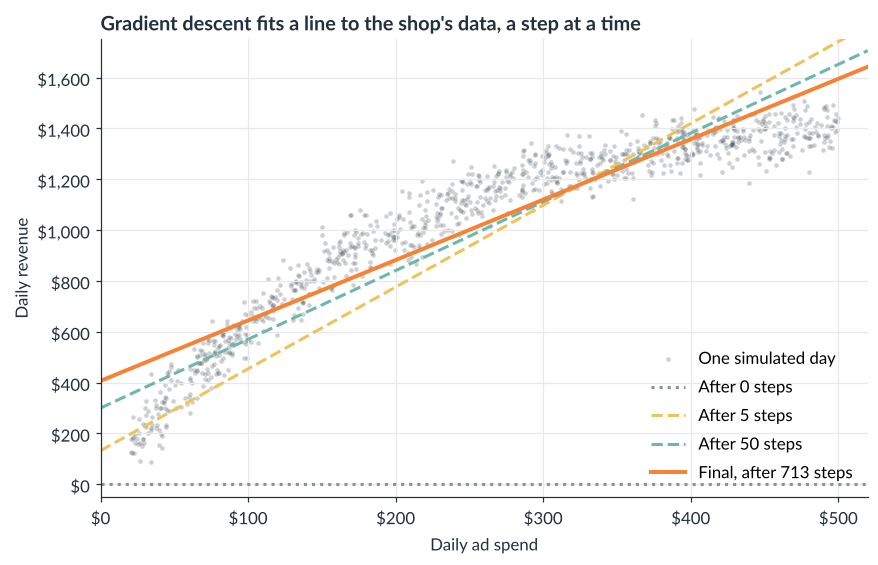

In [16]:
def line_loss(b, x, y=None):
    y = revenue if y is None else y
    return float(np.mean((b[0] + b[1] * x - y) ** 2))

def line_gradient(b, x, y=None):
    y = revenue if y is None else y
    error = b[0] + b[1] * x - y
    return np.array([2 * error.mean(), 2 * (error * x).mean()])

x100 = spend / 100   # ad spend in hundreds of dollars
fit_line = descend(lambda b: line_gradient(b, x100), lambda b: line_loss(b, x100), [0.0, 0.0], G["line_rate"])
b_gd = fit_line["path"][-1]

# The textbook formula (least squares) for comparison
b_formula = np.linalg.lstsq(np.column_stack([np.ones_like(x100), x100]), revenue, rcond=None)[0]

# Check the hand-written gradient against the tiny-step estimate
b_test, h = np.array([300.0, 150.0]), 1e-4
fd_line = np.array([(line_loss(b_test + [h, 0], x100) - line_loss(b_test - [h, 0], x100)) / (2 * h),
                    (line_loss(b_test + [0, h], x100) - line_loss(b_test - [0, h], x100)) / (2 * h)])
LINE_GRAD_ERR = np.abs(fd_line - line_gradient(b_test, x100)).max() / np.abs(fd_line).max()

print(f"Gradient descent: {fit_line['steps']} steps, converged = {fit_line['converged']}")
print(f"  intercept ${b_gd[0]:,.2f}, rate ${b_gd[1]:,.2f} per extra $100 of ad spend")
print(f"Textbook formula:")
print(f"  intercept ${b_formula[0]:,.2f}, rate ${b_formula[1]:,.2f} per extra $100 of ad spend")
print(f"Largest difference: ${np.abs(b_gd - b_formula).max():.4f}")
print(f"Typical miss (RMSE): ${np.sqrt(fit_line['loss'][-1]):,.2f} a day")

fig, ax = plt.subplots(figsize=(9, 5.4))
ax.scatter(spend, revenue, s=9, color=NAVY, alpha=0.22, linewidth=0, label="One simulated day")
s_line = np.array([0, 520])
shown = [(0, GRAY, ":"), (5, GOLD, "--"), (50, TEAL, "--"), (fit_line["steps"], ORANGE, "-")]
for step, col, ls in shown:
    b = fit_line["path"][step]
    ax.plot(s_line, b[0] + b[1] * s_line / 100, color=col, lw=2.6 if ls == "-" else 2, ls=ls,
            label=f"After {step} steps" if step != fit_line["steps"] else f"Final, after {step} steps")
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Daily ad spend"); ax.set_ylabel("Daily revenue")
ax.set_xlim(0, 520); ax.set_ylim(-50, 1750)
ax.legend(loc="lower right")
ax.set_title("Gradient descent fits a line to the shop's data, a step at a time")
save(fig, "fig07_line_fit.png")
plt.show()

The line starts flat at zero, swings up fast in the first few steps, and then makes smaller and smaller corrections. It ends on the same line the textbook formula gives, to within a fraction of a cent.

For a straight line, the formula is faster and you should use it. The point here is to see gradient descent work on a problem where we already know the answer.

Now look at the terrain this model and data created. Because the line has two settings, its loss surface is a map I can draw, with the intercept on one axis and the rate on the other. Elevation is the loss. Read it exactly like the topographic map in Section 2.

Saved figures/fig08_loss_surface.png


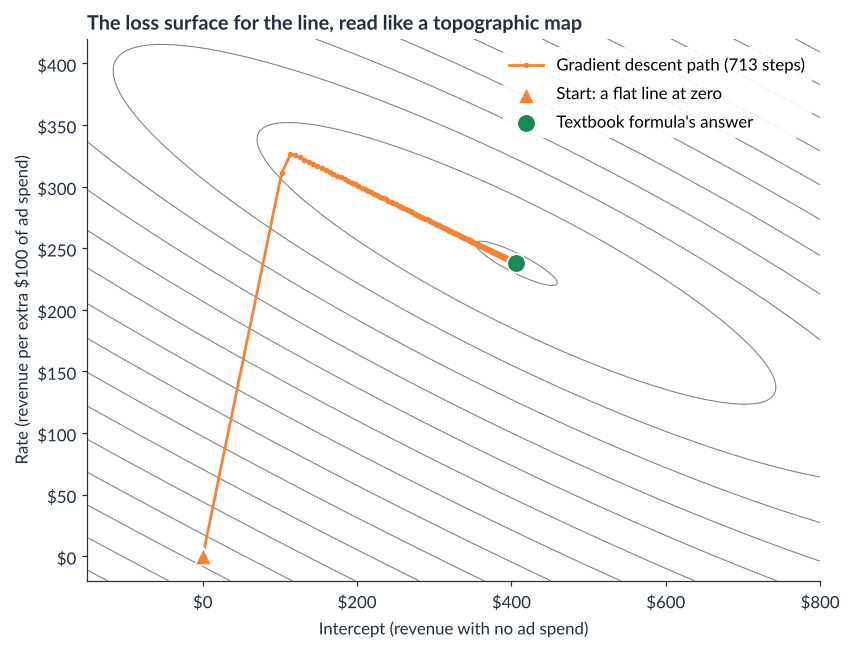

In [17]:
def loss_grid(x, b0_range, b1_range, n=220):
    # Average squared error for every pair of settings on a grid
    b0, b1 = np.linspace(*b0_range, n), np.linspace(*b1_range, n)
    B0, B1 = np.meshgrid(b0, b1)
    L = (B0 ** 2 + 2 * B0 * B1 * x.mean() + B1 ** 2 * (x ** 2).mean()
         - 2 * B0 * revenue.mean() - 2 * B1 * (x * revenue).mean() + (revenue ** 2).mean())
    return B0, B1, L

def draw_loss_map(ax, x, b0_range, b1_range, n_levels=16):
    # Contours of equal loss, spaced so the "typical miss" (RMSE) rises by the same amount between lines
    B0, B1, L = loss_grid(x, b0_range, b1_range)
    rmse = np.sqrt(L)
    levels = np.linspace(rmse.min() * 1.02, rmse.max() * 0.98, n_levels)
    ax.contour(B0, B1, rmse, levels=levels, colors=NAVY, linewidths=0.7, alpha=0.6)
    ax.grid(False)
    return rmse

fig, ax = plt.subplots(figsize=(8.6, 6.4))
draw_loss_map(ax, x100, (-150, 800), (-20, 420))
ax.plot(fit_line["path"][:, 0], fit_line["path"][:, 1], "-o", color=ORANGE, lw=1.8, ms=2.6, zorder=5,
        label=f"Gradient descent path ({fit_line['steps']} steps)")
ax.scatter(0, 0, marker="^", s=130, facecolor=ORANGE, edgecolor="white", linewidth=1.2, zorder=6, label="Start: a flat line at zero")
ax.scatter(*b_formula, marker="o", s=150, facecolor=GREEN, edgecolor="white", linewidth=1.2, zorder=6, label="Textbook formula's answer")
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Intercept (revenue with no ad spend)"); ax.set_ylabel("Rate (revenue per extra $100 of ad spend)")
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title("The loss surface for the line, read like a topographic map")
save(fig, "fig08_loss_surface.png")
plt.show()

This is a loss surface, and it reads like the terrain. Each contour line connects settings that are equally wrong. The green circle is the lowest point, where the line fits best.

One caution about reading it: the two axes are in different units and aren't drawn to the same scale, so the path doesn't look like it crosses the contours at right angles the way it did on the terrain. It does, once the scales match.

Two things are different from the terrain in Section 2. First, there's only one low point and no depression. A straight line with squared error always gives a single bowl, so gradient descent can't get stuck. Second, the bowl is stretched into a long valley. The path drops quickly down the steep side, then turns and creeps along the valley floor. Most of its steps are spent on that last stretch.

That stretched shape comes from the units, which is the next topic.

## 9. Feature scaling: fixing a distorted map

I measured ad spend in hundreds of dollars in the last section without saying why. Here's why. The cell below fits the same line to the same data three ways, changing only the units of ad spend:

- **Raw dollars.** Spend runs from 20 to 500.
- **Hundreds of dollars.** Spend runs from 0.2 to 5.
- **Standardized.** Subtract the average spend and divide by the standard deviation, so spend is centered on zero and mostly runs from about -1.7 to 1.7.

In [18]:
z = (spend - spend.mean()) / spend.std()   # standardized ad spend
runs = {
    "Raw dollars": (spend, G["line_rate_raw"]),
    "Hundreds of dollars": (x100, G["line_rate"]),
    "Standardized": (z, G["line_rate_standardized"]),
}
scale_fits = {name: descend(lambda b, x=x: line_gradient(b, x), lambda b, x=x: line_loss(b, x), [0.0, 0.0], r)
              for name, (x, r) in runs.items()}

def to_dollars(name, b):
    # Convert the fitted settings back to: intercept in dollars, revenue per extra ad dollar
    if name == "Raw dollars":
        return b[0], b[1]
    if name == "Hundreds of dollars":
        return b[0], b[1] / 100
    return b[0] - b[1] * spend.mean() / spend.std(), b[1] / spend.std()

rows = []
for name, (x, r) in runs.items():
    f = scale_fits[name]
    i0, per_dollar = to_dollars(name, f["path"][-1])
    rows.append({"Ad spend measured in": name, "Learning rate": np.format_float_positional(r, trim="-"), "Steps": f"{f['steps']:,}",
                 "Converged": "Yes" if f["converged"] else "No, hit the step limit",
                 "Revenue per extra ad dollar": f"${per_dollar:.2f}", "Intercept": f"${i0:,.0f}",
                 "Typical miss (RMSE)": f"${np.sqrt(f['loss'][-1]):,.0f}"})
t2 = pd.DataFrame(rows)
render_table("table02_feature_scaling.png", "Same data, same line, three sets of units",
             f"The textbook formula gives ${b_formula[1] / 100:.2f} per extra ad dollar and an intercept of ${b_formula[0]:,.0f}", t2, [20, 9, 8, 14, 16, 10, 12])
t2

Saved tables/table02_feature_scaling.png and a CSV copy


,Ad spend measured in,Learning rate,Steps,Converged,Revenue per extra ad dollar,Intercept,Typical miss (RMSE)
0,Raw dollars,0.00001,"10,000","No, hit the step limit",$3.54,$18,$224
1,Hundreds of dollars,0.05,713,Yes,$2.38,$406,$126
2,Standardized,0.3,22,Yes,$2.38,$406,$126


Saved figures/fig09_feature_scaling.png


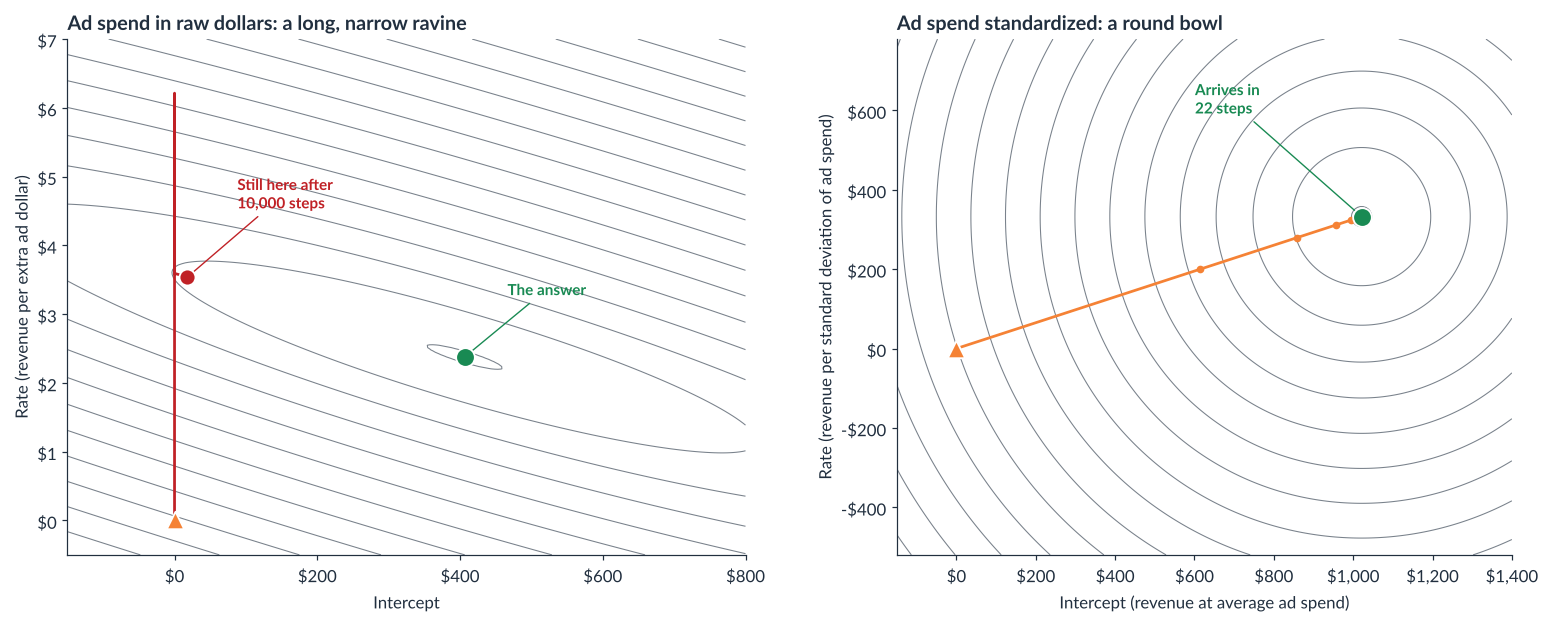

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))
# Left: raw dollars. Right: standardized.
ax = axes[0]
f = scale_fits["Raw dollars"]
draw_loss_map(ax, spend, (-150, 800), (-0.5, 7.0))
ax.plot(f["path"][:, 0], f["path"][:, 1], "-", color=RED, lw=1.8, zorder=5)
ax.scatter(0, 0, marker="^", s=130, facecolor=ORANGE, edgecolor="white", linewidth=1.2, zorder=6)
ax.scatter(b_formula[0], b_formula[1] / 100, marker="o", s=150, facecolor=GREEN, edgecolor="white", linewidth=1.2, zorder=6)
ax.scatter(*f["path"][-1], marker="o", s=110, facecolor=RED, edgecolor="white", linewidth=1.2, zorder=6)
ax.annotate(f"Still here after\n{f['steps']:,} steps", f["path"][-1], xytext=(f["path"][-1][0] + 70, f["path"][-1][1] + 1.0),
            fontsize=10, color=RED, fontweight="bold", arrowprops=dict(arrowstyle="-", color=RED, lw=0.9))
ax.annotate("The answer", (b_formula[0], b_formula[1] / 100), xytext=(b_formula[0] + 60, b_formula[1] / 100 + 0.9),
            fontsize=10, color=GREEN, fontweight="bold", arrowprops=dict(arrowstyle="-", color=GREEN, lw=0.9))
ax.xaxis.set_major_formatter(dollars)
ax.yaxis.set_major_formatter(lambda v, pos: f"${v:.0f}")
ax.set_xlabel("Intercept"); ax.set_ylabel("Rate (revenue per extra ad dollar)")
ax.set_title("Ad spend in raw dollars: a long, narrow ravine")

ax = axes[1]
f = scale_fits["Standardized"]
b_std_formula = np.array([revenue.mean(), b_formula[1] / 100 * spend.std()])
draw_loss_map(ax, z, (-150, 1400), (-520, 780))
ax.plot(f["path"][:, 0], f["path"][:, 1], "-o", color=ORANGE, lw=1.8, ms=4, zorder=5)
ax.scatter(0, 0, marker="^", s=130, facecolor=ORANGE, edgecolor="white", linewidth=1.2, zorder=6)
ax.scatter(*b_std_formula, marker="o", s=150, facecolor=GREEN, edgecolor="white", linewidth=1.2, zorder=6)
ax.annotate(f"Arrives in\n{f['steps']} steps", b_std_formula, xytext=(b_std_formula[0] - 420, b_std_formula[1] + 260),
            fontsize=10, color=GREEN, fontweight="bold", arrowprops=dict(arrowstyle="-", color=GREEN, lw=0.9))
ax.set_aspect("equal")
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Intercept (revenue at average ad spend)"); ax.set_ylabel("Rate (revenue per standard deviation of ad spend)")
ax.set_title("Ad spend standardized: a round bowl")
fig.tight_layout()
save(fig, "fig09_feature_scaling.png")
plt.show()

Nothing about the shop changed between those three runs. Only the units did.

With ad spend in **raw dollars**, the loss surface is a ravine so narrow that its contour lines look parallel. A tiny change in the rate moves the predictions for every day by a lot, so that direction is extremely steep. A change in the intercept matters far less, so that direction is nearly flat. The learning rate has to be tiny to keep from bouncing off the ravine walls, and with a tiny learning rate the walk along the floor takes forever. After 10,000 steps it hasn't come close. It reports about \$3.54 per ad dollar when the real answer is \$2.38, and an intercept of \$18 when the real one is about \$406.

That wrong answer is still an answer. If nobody checks whether the model converged, \$3.54 goes into the report.

With ad spend in **hundreds of dollars**, the ravine widens into the valley from Section 8 and the walk finishes in about 700 steps.

With ad spend **standardized**, the surface is a round bowl. The fall line points straight at the bottom from everywhere, and the walk takes about 20 steps.

A map drawn at a badly distorted scale makes every leg harder to navigate. Fixing the scale is called **feature scaling**, and standardizing is the most common way to do it. Marketing data mixes impressions in the millions with rates in fractions of a percent, so it's rarely optional. Nearly every neural network pipeline scales its inputs first.

One caution. A standardized model reports its rate "per standard deviation of ad spend," which is correct and means nothing to a client. The table converts everything back to dollars, and so should you.

## 10. Stochastic gradient descent

Everything so far has a hidden cost. To compute the gradient for one step, the code used every row of data. That's like surveying the whole hillside before each stride. With 1,000 rows it doesn't matter. With hundreds of millions of ad impressions, one step would take all day.

**Stochastic gradient descent (SGD)** makes a trade. It estimates the gradient from one randomly chosen row, takes a step, and picks another row. ("Stochastic" just means random.) Each estimate is rough. On average they point the right way, and each one costs almost nothing.

**Mini-batch gradient descent** is the middle ground and the usual choice. It estimates the gradient from a small random handful of rows, often 32 to 256. In practice people call this SGD too.

```
batch:       gradient from all rows          (exact, slow per step)
stochastic:  gradient from 1 random row      (noisy, fast per step)
mini-batch:  gradient from a small sample    (the usual choice)
```

One more word: an **epoch** is one full pass through the data. In one epoch over 1,000 rows, batch gradient descent takes 1 step, mini-batch with 32 rows takes 32 steps, and single-row SGD takes 1,000.

The cell below fits the line from Section 8 all three ways, with the same learning rate and the same 50 epochs.

Batch (all 1,000 rows)       50 steps in 50 epochs | rate $ 313.64 per $100 (formula $237.71) | typical miss $172.45 (best possible $125.76)
Mini-batch (32 rows)      1,600 steps in 50 epochs | rate $ 238.22 per $100 (formula $237.71) | typical miss $125.77 (best possible $125.76)
Stochastic (1 row)       50,000 steps in 50 epochs | rate $ 243.97 per $100 (formula $237.71) | typical miss $128.81 (best possible $125.76)


Saved figures/fig10_sgd.png


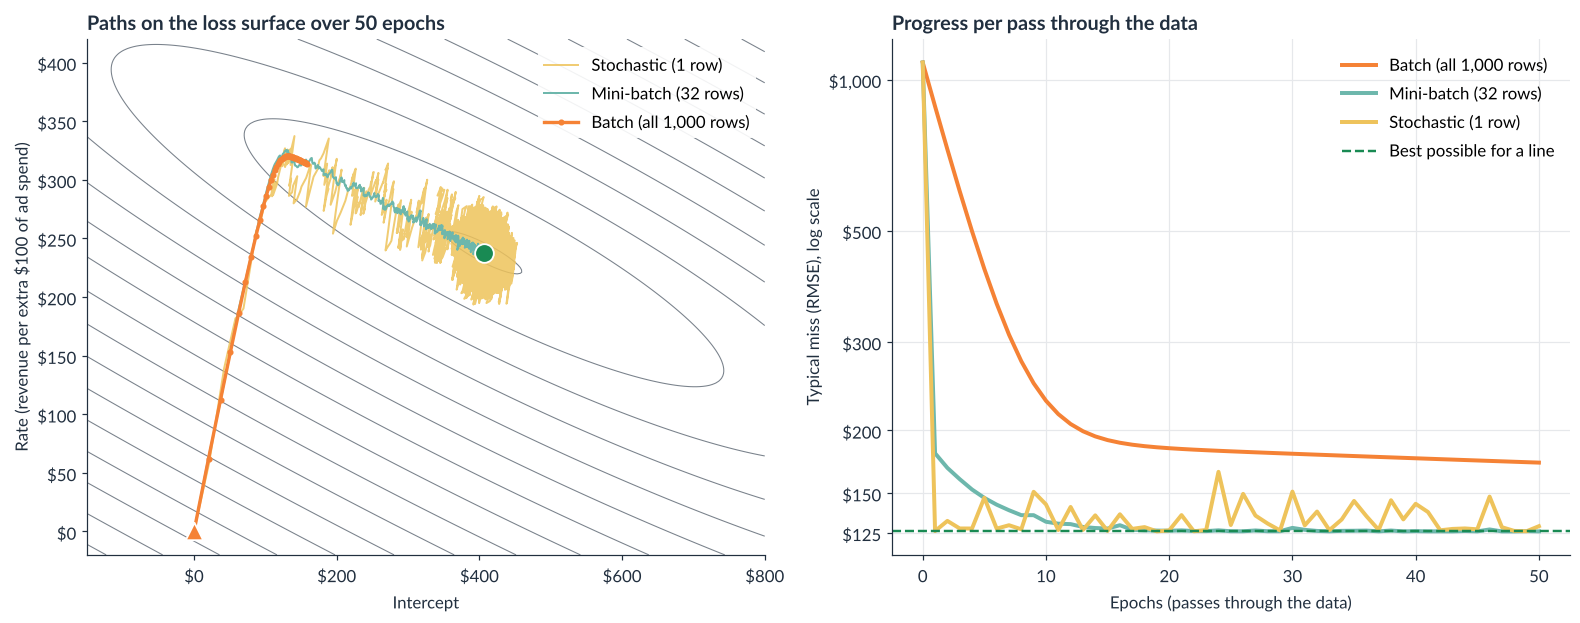

In [20]:
def sgd_line(x, y, rate, batch_size, epochs, seed, decay=0.0):
    # Gradient descent on the line, using only batch_size rows to estimate each gradient.
    # The same slope formulas as before, applied to a random sample of rows.
    rng = np.random.default_rng(seed)
    b, n, t = np.zeros(2), len(y), 0
    path, epoch_loss = [b.copy()], [line_loss(b, x, y)]
    for _ in range(epochs):
        order = rng.permutation(n)                      # shuffle the rows each epoch
        for i in range(0, n, batch_size):
            rows = order[i:i + batch_size]
            error = b[0] + b[1] * x[rows] - y[rows]
            g = np.array([2 * error.mean(), 2 * (error * x[rows]).mean()])
            b = b - rate / (1 + decay * t) * g          # with decay > 0, the steps shorten over time
            t += 1
            path.append(b.copy())
        epoch_loss.append(line_loss(b, x, y))
    return {"path": np.array(path), "epoch_loss": np.array(epoch_loss), "b": b, "steps": t}

n_rows = len(revenue)
variants = [("Batch (all 1,000 rows)", n_rows, ORANGE), ("Mini-batch (32 rows)", 32, TEAL), ("Stochastic (1 row)", 1, GOLD)]
sgd_runs, sgd_seconds = {}, {}
for name, size, _ in variants:
    t0 = time.perf_counter()
    sgd_runs[name] = sgd_line(x100, revenue, B["rate"], size, B["epochs"], SEED)
    sgd_seconds[name] = time.perf_counter() - t0
best_rmse = np.sqrt(line_loss(b_formula, x100))
for name, size, _ in variants:
    r = sgd_runs[name]
    print(f"{name:24s} {r['steps']:>6,} steps in {B['epochs']} epochs | rate ${r['b'][1]:7.2f} per $100 "
          f"(formula ${b_formula[1]:.2f}) | typical miss ${np.sqrt(r['epoch_loss'][-1]):,.2f} (best possible ${best_rmse:,.2f})")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.8))
ax = axes[0]
draw_loss_map(ax, x100, (-150, 800), (-20, 420))
for name, size, col in reversed(variants):
    p = sgd_runs[name]["path"]
    ax.plot(p[:, 0], p[:, 1], "-", color=col, lw=2.2 if size == n_rows else 1.3, alpha=1 if size != 1 else 0.85,
            marker="o" if size == n_rows else None, ms=3, zorder=5 if size != 1 else 4, label=name)
ax.scatter(0, 0, marker="^", s=130, facecolor=ORANGE, edgecolor="white", linewidth=1.2, zorder=6)
ax.scatter(*b_formula, marker="o", s=150, facecolor=GREEN, edgecolor="white", linewidth=1.2, zorder=7)
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Intercept"); ax.set_ylabel("Rate (revenue per extra $100 of ad spend)")
ax.legend(loc="upper right", frameon=True, facecolor="white", edgecolor="none", framealpha=0.9)
ax.set_title(f"Paths on the loss surface over {B['epochs']} epochs")
ax = axes[1]
for name, size, col in variants:
    ax.plot(np.arange(B["epochs"] + 1), np.sqrt(sgd_runs[name]["epoch_loss"]), color=col, lw=2.6, label=name)
ax.axhline(best_rmse, color=GREEN, lw=1.6, ls="--", label="Best possible for a line")
ax.set_yscale("log")
ax.set_yticks([125, 150, 200, 300, 500, 1000]); ax.minorticks_off()
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Epochs (passes through the data)"); ax.set_ylabel("Typical miss (RMSE), log scale")
ax.legend(loc="upper right")
ax.set_title("Progress per pass through the data")
fig.tight_layout()
save(fig, "fig10_sgd.png")
plt.show()

Look at the right-hand chart first. After 50 passes through the data, batch gradient descent has taken only 50 steps and is still far from done. Mini-batch has taken 1,600 steps and single-row SGD has taken 50,000. Both got close to the best possible line within the first few passes. For the same amount of data handled, the noisy methods make far more progress.

Now the left-hand chart. The batch path is smooth. The mini-batch path wobbles a little. The single-row path staggers, and when it reaches the bottom it doesn't stop. It keeps wandering around the low point, because each single row keeps pulling it in a slightly different direction.

That wandering is the cost of the noise. The standard fix is a **learning rate schedule** that shortens the steps over time:

```
learning rate at step t = starting rate / (1 + decay * t)
```

Big steps early cover ground. Small steps later let the walk settle. The cell below repeats the noisy runs with 20 different random seeds, with and without a schedule, to see how much the answers vary.

In [21]:
rows, seed_results = [], {}
for name, size in [("Stochastic (1 row)", 1), ("Mini-batch (32 rows)", 32)]:
    for label, decay in [("Constant learning rate", 0.0), ("With a schedule", B["decay"])]:
        rates = np.array([sgd_line(x100, revenue, B["rate"], size, B["epochs"], SEED + s, decay)["b"][1]
                          for s in range(B["n_seeds"])])
        seed_results[(name, label)] = rates
        rows.append({"Method": name, "Learning rate": label, "Lowest rate found": f"${rates.min():.2f}",
                     "Highest rate found": f"${rates.max():.2f}", "Spread (std. dev.)": f"${rates.std():.2f}",
                     "Farthest from the formula": f"{np.abs(rates / b_formula[1] - 1).max():.1%}"})
seed_table = pd.DataFrame(rows)
print(f"Rate (revenue per extra $100 of ad spend) across {B['n_seeds']} random seeds. The formula's answer is ${b_formula[1]:.2f}.")
print(seed_table.to_string(index=False))
print("\nSeconds for 50 epochs on this machine (yours will differ):",
      {k: round(v, 3) for k, v in sgd_seconds.items()})

Rate (revenue per extra $100 of ad spend) across 20 random seeds. The formula's answer is $237.71.
              Method          Learning rate Lowest rate found Highest rate found Spread (std. dev.) Farthest from the formula
  Stochastic (1 row) Constant learning rate           $209.70            $258.64             $12.16                     11.8%
  Stochastic (1 row)        With a schedule           $235.41            $239.76              $1.08                      1.0%
Mini-batch (32 rows) Constant learning rate           $232.10            $242.84              $2.41                      2.4%
Mini-batch (32 rows)        With a schedule           $237.34            $241.44              $0.97                      1.6%

Seconds for 50 epochs on this machine (yours will differ): {'Batch (all 1,000 rows)': 0.002, 'Mini-batch (32 rows)': 0.013, 'Stochastic (1 row)': 0.386}


With a constant learning rate, single-row SGD gives a noticeably different answer each time it's run. The schedule cuts that spread to a small fraction. Mini-batch is steadier to begin with, because averaging 32 rows smooths out most of the noise.

Three more things to know about SGD.

**The noise can help.** A wobbling walk can bounce out of a shallow depression that would trap a smooth one. That's one of the standard defenses against the local minimums in Section 7.

**The noise makes results depend on the random seed.** Two runs of the same code give slightly different models unless the seed is fixed. If a model's output is going into a report, fix the seed and write it down.

**It can learn from a stream.** Because each step needs only a handful of rows, a model can take a step whenever new data arrives. That's how ad platforms keep their bidding models current while a campaign is running.

The idea goes back to a 1951 paper by Herbert Robbins and Sutton Monro on finding answers from noisy measurements. Leon Bottou's work explains why it suits very large data sets: when data is plentiful, many cheap, rough steps beat a few expensive, exact ones.

## 11. Momentum and Adam

Two upgrades to the basic step rule show up everywhere.

**Momentum.** A runner coming downhill carries speed. Momentum does the same thing: each step keeps part of the previous step and adds the new gradient to it.

```
velocity     = 0.9 * velocity + gradient
new position = old position - learning rate * velocity
```

Steps that keep pointing the same way build up speed. Steps that zigzag cancel each other out. And a walk with speed can coast across a small dip.

**Adam.** Adam keeps a running average of the gradient, as momentum does, and also a running average of the squared gradient. It uses the second one to give every setting its own step size: settings with consistently large gradients get smaller steps, and settings with small gradients get larger ones. It's the usual default for training neural networks. The name comes from "adaptive moment estimation."

Let's go back to the terrain and start all three from start B, the one that got stuck.

Plain gradient descent     23 steps, ended in the depression at 21.1 m
Momentum                  224 steps, ended in the lowest point at 0.2 m
Adam                      239 steps, ended in the depression at 21.1 m
Adam with a learning rate three times larger (0.3): ended in the lowest point


Saved figures/fig11_optimizers.png


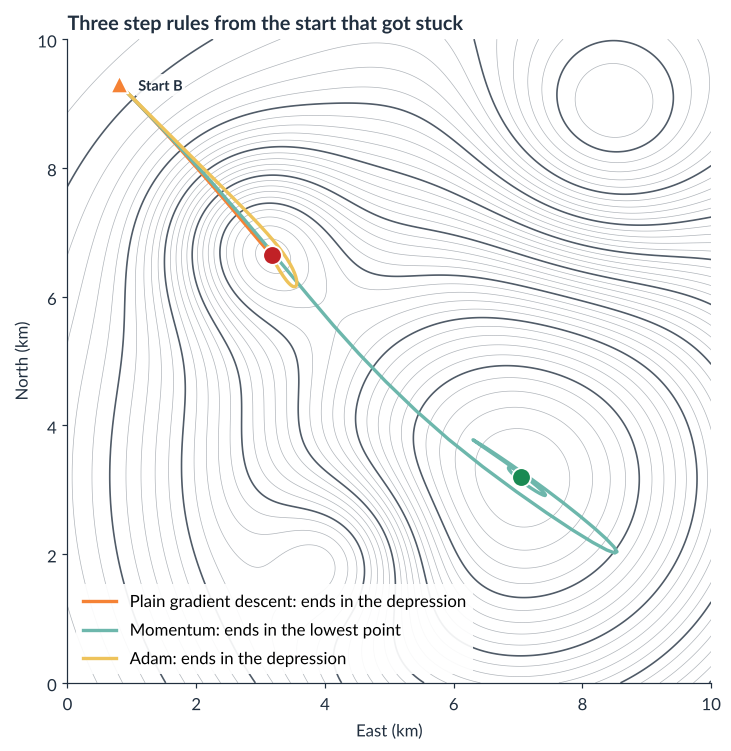

In [22]:
opt_walks = {
    "Plain gradient descent": (descend(terrain_gradient, elevation, START_B, G["terrain_rate"]), ORANGE),
    "Momentum": (descend(terrain_gradient, elevation, START_B, M["momentum_rate"], optimizer="momentum"), TEAL),
    "Adam": (descend(terrain_gradient, elevation, START_B, M["adam_rate"], optimizer="adam"), GOLD),
}
def where(p):
    return ("the lowest point" if np.linalg.norm(p - LOW) < 0.05 else
            "the depression" if np.linalg.norm(p - DEP) < 0.05 else "somewhere else")
for name, (w, _) in opt_walks.items():
    print(f"{name:24s} {w['steps']:>4} steps, ended in {where(w['path'][-1])} at {w['loss'][-1]:.1f} m")
adam_bigger = descend(terrain_gradient, elevation, START_B, 3 * M["adam_rate"], optimizer="adam")
print(f"Adam with a learning rate three times larger ({3 * M['adam_rate']:g}): ended in {where(adam_bigger['path'][-1])}")

fig, ax = plt.subplots(figsize=(7.6, 7.6))
draw_map(ax, labels=False, alpha=0.8)
for name, (w, col) in opt_walks.items():
    ax.plot(w["path"][:, 0], w["path"][:, 1], "-", color=col, lw=2.2, zorder=5,
            label=f"{name}: ends in {where(w['path'][-1])}")
mark(ax, START_B, "start", "Start B", dx=0.3, dy=-0.1)
mark(ax, LOW, "low"); mark(ax, DEP, "stuck")
ax.legend(loc="lower left", frameon=True, facecolor="white", edgecolor="none", framealpha=0.92)
ax.set_title("Three step rules from the start that got stuck")
save(fig, "fig11_optimizers.png")
plt.show()

Plain gradient descent rolls into the depression and stays, as before. Momentum arrives with enough speed to carry over the far rim, across the saddle, and down into the basin. It overshoots the lowest point, swings back, and settles.

Adam, at the setting I chose, stays in the depression. With a learning rate three times larger it gets out. I've left the first result in the chart on purpose. No step rule is guaranteed to escape a local minimum, and whether one does depends on its settings and on the shape of the ground. I also shaped this terrain so that momentum would make it out. A deeper depression would trap it too.

There's a whole family of these methods (AdaGrad, RMSProp, AdamW, and more). Sebastian Ruder's overview, listed in the article's resources, is a good guide to the rest.

## 12. A small neural network

Back to the shop. The straight line in Section 8 was the wrong shape for the data. Revenue bends as ad spend rises, and a line can't bend.

A **neural network** can. A network is a model with many weights arranged in layers. The one here is about as small as they come: one input (ad spend), one hidden layer of 8 units, and one output (predicted revenue). That's 25 weights in all. Each hidden unit draws its own S-shaped curve, and the output adds those curves together.

For a network there's no textbook formula for the best weights. Gradient descent is the only practical way to train one. Its loss surface has one dimension per weight, so nobody can draw it. Everything from the map still applies: a location, an elevation, a gradient, a step.

The hard part is computing the gradient. **Backpropagation** does it in two passes:

1. **Forward pass.** Run the data through the network to get predictions, and measure the loss.
2. **Backward pass.** Work backward from the loss, one layer at a time, using the chain rule from calculus to get the slope for every weight.

```
slope for a weight = (how the loss changes with the output)
                   * (how the output changes with the hidden unit)
                   * (how the hidden unit changes with the weight)
```

Backpropagation and gradient descent are two separate jobs, and they're often confused. Backpropagation computes the gradient. Gradient descent uses it to take the step.

In [23]:
xs = (spend - spend.mean()) / spend.std()          # standardized input (Section 9)
ys = (revenue - revenue.mean()) / revenue.std()    # standardized output, converted back to dollars for every chart

def init_net(seed):
    # Random starting weights. A different seed is a different starting point on the loss surface.
    rng, h = np.random.default_rng(seed), N["hidden_units"]
    return {"W1": rng.normal(0, 1.0, h), "b1": rng.normal(0, 1.0, h), "W2": rng.normal(0, 0.5, h), "b2": np.zeros(1)}

def forward(net, x):
    hidden = np.tanh(np.outer(x, net["W1"]) + net["b1"])   # each hidden unit draws an S-shaped curve
    return hidden @ net["W2"] + net["b2"][0], hidden       # the output adds them up

def net_loss(net, x, y):
    return float(np.mean((forward(net, x)[0] - y) ** 2))

def backprop(net, x, y):
    # The slope of the loss for every weight, by the chain rule, working backward from the output
    out, hidden = forward(net, x)
    d_out = 2 * (out - y) / len(y)                          # how the loss changes with each prediction
    d_hidden = np.outer(d_out, net["W2"]) * (1 - hidden ** 2)   # passed back through the S-curve
    return {"W1": d_hidden.T @ x, "b1": d_hidden.sum(axis=0), "W2": hidden.T @ d_out, "b2": np.array([d_out.sum()])}

def predict_revenue(net, s):
    # Predicted daily revenue in dollars at daily ad spend s
    return forward(net, (np.asarray(s, dtype=float) - spend.mean()) / spend.std())[0] * revenue.std() + revenue.mean()

def train_net(seed, epochs=None, snapshots=()):
    # Mini-batch stochastic gradient descent, written out step by step
    epochs = N["epochs"] if epochs is None else epochs
    net, rng, n = init_net(seed), np.random.default_rng(seed + 1000), len(ys)
    history, saved = [net_loss(net, xs, ys)], {}
    if 0 in snapshots:
        saved[0] = {k: v.copy() for k, v in net.items()}
    for epoch in range(1, epochs + 1):
        order = rng.permutation(n)
        for i in range(0, n, N["batch_size"]):
            rows = order[i:i + N["batch_size"]]
            grads = backprop(net, xs[rows], ys[rows])       # backpropagation finds the gradient
            for k in net:
                net[k] = net[k] - N["rate"] * grads[k]      # gradient descent takes the step
        history.append(net_loss(net, xs, ys))
        if epoch in snapshots:
            saved[epoch] = {k: v.copy() for k, v in net.items()}
    return net, np.array(history), saved

# Check backpropagation against the tiny-step estimate, for every one of the weights
check_net, h = init_net(SEED), 1e-6
analytic = backprop(check_net, xs[:64], ys[:64])
worst, n_weights = 0.0, 0
for k in check_net:
    for i in range(check_net[k].size):
        up = {kk: vv.copy() for kk, vv in check_net.items()}; up[k][i] += h
        dn = {kk: vv.copy() for kk, vv in check_net.items()}; dn[k][i] -= h
        estimate = (net_loss(up, xs[:64], ys[:64]) - net_loss(dn, xs[:64], ys[:64])) / (2 * h)
        worst = max(worst, abs(estimate - analytic[k][i])); n_weights += 1
BACKPROP_ERR, N_WEIGHTS = worst, n_weights
print(f"Backpropagation vs. tiny-step estimate across all {N_WEIGHTS} weights: largest difference {BACKPROP_ERR:.1e}")

Backpropagation vs. tiny-step estimate across all 25 weights: largest difference 6.0e-11


Trained for 1,000 epochs (32,000 steps) in 0.9 seconds


Typical miss (RMSE): straight line $125.76 | network $60.86 | noise built into the data $60.00
  after     0 epochs: typical miss $238.28
  after     1 epoch : typical miss $128.61
  after    10 epochs: typical miss $88.88
  after   100 epochs: typical miss $64.87
  after 1,000 epochs: typical miss $60.86
Across 10 random starts, final typical miss ranged from $60.77 to $61.16


scikit-learn's MLPRegressor on the same data: typical miss $60.99


Saved figures/fig12_network_learning.png


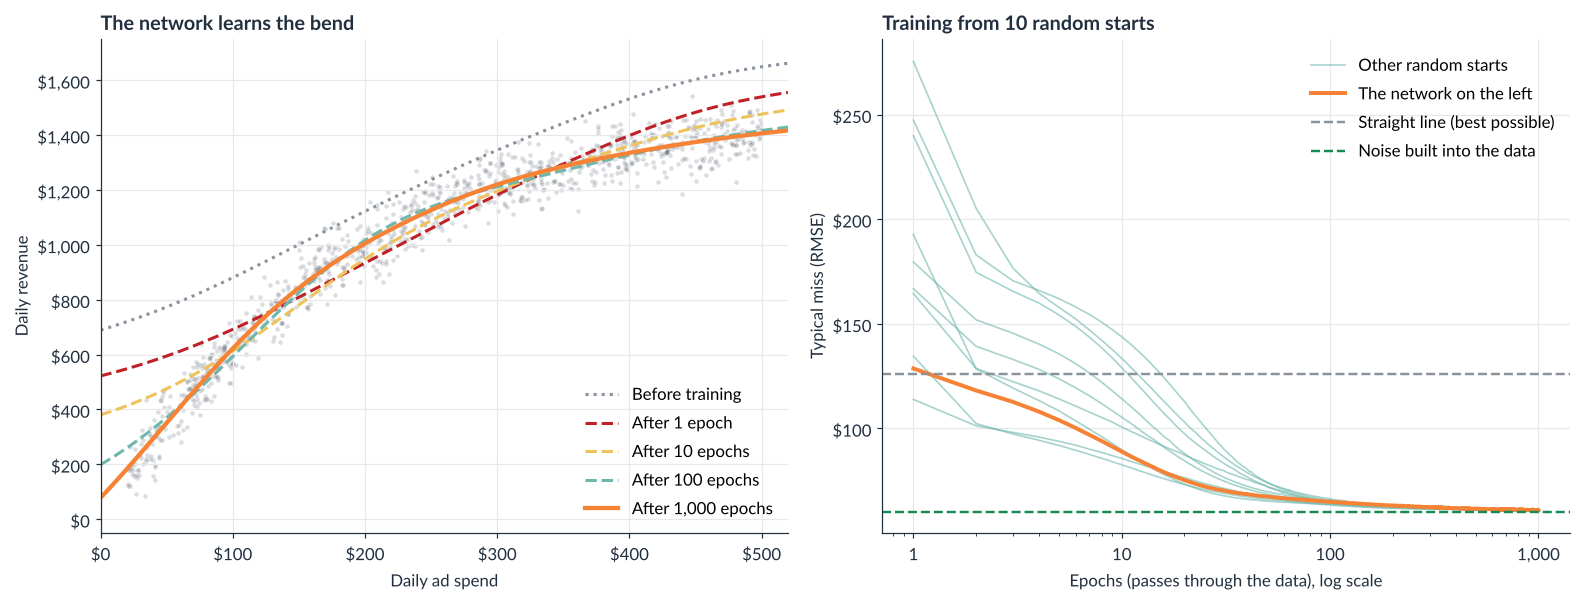

In [24]:
t0 = time.perf_counter()
net, net_history, net_saved = train_net(SEED, snapshots=N["snapshots"])
print(f"Trained for {N['epochs']:,} epochs ({N['epochs'] * int(np.ceil(len(ys) / N['batch_size'])):,} steps) "
      f"in {time.perf_counter() - t0:.1f} seconds")

# The same network from several random starting points
starts = [train_net(SEED + s) for s in range(N["n_starts"])]
start_nets = [s[0] for s in starts]
start_hist = np.array([s[1] for s in starts])

to_rmse = lambda mse: np.sqrt(mse) * revenue.std()      # standardized loss -> typical miss in dollars
line_rmse = np.sqrt(line_loss(b_formula, x100))
noise_rmse = A["revenue_noise"]
print(f"Typical miss (RMSE): straight line ${line_rmse:,.2f} | network ${to_rmse(net_history[-1]):,.2f} | "
      f"noise built into the data ${noise_rmse:,.2f}")
for e in N["snapshots"]:
    print(f"  after {e:>5,} epoch{'s' if e != 1 else ' '}: typical miss ${to_rmse(net_history[e]):,.2f}")
final = to_rmse(start_hist[:, -1])
print(f"Across {N['n_starts']} random starts, final typical miss ranged from ${final.min():,.2f} to ${final.max():,.2f}")

# Reference: scikit-learn's neural network, trained with Adam
with warnings.catch_warnings():
    warnings.simplefilter("ignore", ConvergenceWarning)
    sk_net = MLPRegressor(hidden_layer_sizes=(N["hidden_units"],), activation="tanh", solver="adam",
                          max_iter=5000, tol=1e-7, n_iter_no_change=50, random_state=SEED).fit(xs.reshape(-1, 1), ys)
sk_rmse = to_rmse(np.mean((sk_net.predict(xs.reshape(-1, 1)) - ys) ** 2))
print(f"scikit-learn's MLPRegressor on the same data: typical miss ${sk_rmse:,.2f}")

s_grid = np.linspace(0, 520, 261)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
ax = axes[0]
ax.scatter(spend, revenue, s=9, color=NAVY, alpha=0.16, linewidth=0)
snap_style = {0: (GRAY, ":"), 1: (RED, "--"), 10: (GOLD, "--"), 100: (TEAL, "--"), 1000: (ORANGE, "-")}
for e in N["snapshots"]:
    col, ls = snap_style.get(e, (TEAL, "--"))
    ax.plot(s_grid, predict_revenue(net_saved[e], s_grid), color=col, ls=ls, lw=2.8 if ls == "-" else 2,
            label="Before training" if e == 0 else f"After {e:,} epoch{'s' if e != 1 else ''}")
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Daily ad spend"); ax.set_ylabel("Daily revenue")
ax.set_xlim(0, 520); ax.set_ylim(-50, 1750)
ax.legend(loc="lower right")
ax.set_title("The network learns the bend")
ax = axes[1]
ep = np.arange(1, N["epochs"] + 1)
for i, hist in enumerate(start_hist):
    ax.plot(ep, to_rmse(hist[1:]), color=TEAL, lw=1.1, alpha=0.6, label="Other random starts" if i == 1 else None)
ax.plot(ep, to_rmse(net_history[1:]), color=ORANGE, lw=2.6, label="The network on the left")
ax.axhline(line_rmse, color=GRAY, lw=1.6, ls="--", label="Straight line (best possible)")
ax.axhline(noise_rmse, color=GREEN, lw=1.6, ls="--", label="Noise built into the data")
ax.set_xscale("log")
ax.xaxis.set_major_formatter(lambda v, pos: f"{v:,.0f}")
ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Epochs (passes through the data), log scale"); ax.set_ylabel("Typical miss (RMSE)")
ax.legend(loc="upper right")
ax.set_title(f"Training from {N['n_starts']} random starts")
fig.tight_layout()
save(fig, "fig12_network_learning.png")
plt.show()

The left-hand chart shows the network learning. Before training, its random weights draw a curve that has nothing to do with the data. After one pass through the data it has found the upward trend and looks a lot like the straight line. After 10 passes the bend is starting to show. By 100 it follows the data closely, and the remaining 900 passes make small refinements.

The right-hand chart shows the typical miss falling as training goes on. Two reference lines put it in context. The gray line is the best any straight line can do, about \$126 a day. The green line is the noise I built into the data, \$60 a day, which no model can beat. The network ends at about \$61, close to that floor. scikit-learn's version of the same network lands in the same place.

The thin teal lines are the same network trained from other random starting points. They take different routes, and they don't finish at exactly the same loss: the final typical miss ranges from \$60.77 to \$61.16. This loss surface isn't a single bowl. Each run settles into its own low spot. Here the low spots are all about equally good, which is the common case that Section 7 described. The next section shows whether those small differences matter for a decision.

Scale this picture up and you have modern AI. A large language model is trained by the same loop, run as mini-batch stochastic gradient descent in an Adam-style variant, with billions of weights in place of 25.

## 13. From a trained model to a budget

The shop wants to know how much to spend on ads each day. A fitted revenue curve can answer that, and the answer is another derivative.

```
profit = gross margin * predicted revenue - ad spend
best spend is where:  gross margin * (slope of the revenue curve) = 1
```

In words: keep spending until the next ad dollar brings back exactly one dollar of margin. With a 50% gross margin, that's the point where the next ad dollar brings back \$2.00 of revenue. This is the marginal reasoning from Section 3. Economists call it setting marginal revenue equal to marginal cost.

Because the data is simulated, I know the true curve and so the truly best budget. A real shop never has that. It only has the model. The cell below asks each model for its recommendation, then scores every recommendation against the true curve.

In [25]:
budget_grid = np.arange(0, A["spend_range"][1] + 1, 1.0)   # candidate daily budgets, in whole dollars

def recommend(predict):
    # The daily spend a model thinks is most profitable
    return float(budget_grid[np.argmax(C["gross_margin"] * predict(budget_grid) - budget_grid)])

def true_profit(s):
    # What that spend would really earn per day, on average
    return C["gross_margin"] * true_revenue(s) - s

TRUE_BEST = A["spend_scale"] * np.log(C["gross_margin"] * A["revenue_ceiling"] / A["spend_scale"])  # from the formula
line_predict = lambda s: b_formula[0] + b_formula[1] * np.asarray(s, dtype=float) / 100

candidates = [("The true curve (never known in practice)", true_revenue),
              ("Straight line", line_predict)]
for e in [e for e in N["snapshots"] if e > 0]:
    candidates.append((f"Neural network after {e:,} epoch{'s' if e != 1 else ''}", lambda s, e=e: predict_revenue(net_saved[e], s)))
budget = {name: recommend(f) for name, f in candidates}
best_profit = true_profit(TRUE_BEST)
rows = []
for name, s in budget.items():
    left = best_profit - true_profit(s)
    rows.append({"Model": name, "Recommended daily ad spend": f"${s:,.0f}", "Daily profit at that spend": f"${true_profit(s):,.2f}",
                 "Profit left behind per day": f"${left:,.2f}", "Per year": f"${left * 365:,.0f}"})
t3 = pd.DataFrame(rows)
render_table("table03_budget_by_model.png", "What each model tells the shop to spend",
             f"Daily profit is scored against the true curve. The truly best budget is ${TRUE_BEST:,.0f} a day.",
             t3, [34, 14, 14, 14, 10])

start_budgets = np.array([recommend(lambda s, n=n: predict_revenue(n, s)) for n in start_nets])
start_left = best_profit - true_profit(start_budgets)
print(f"Truly best daily spend: ${TRUE_BEST:,.2f}, earning ${best_profit:,.2f} a day")
print(f"Check: gross margin * slope of the true curve at that spend = {C['gross_margin'] * true_revenue_slope(TRUE_BEST):.6f}")
print(f"Across {N['n_starts']} random starts, the fully trained network recommends ${start_budgets.min():,.0f} to "
      f"${start_budgets.max():,.0f} a day, leaving at most ${start_left.max():.2f} a day behind")
t3

Saved tables/table03_budget_by_model.png and a CSV copy
Truly best daily spend: $256.88, earning $313.12 a day
Check: gross margin * slope of the true curve at that spend = 1.000000
Across 10 random starts, the fully trained network recommends $249 to $263 a day, leaving at most $0.18 a day behind


,Model,Recommended daily ad spend,Daily profit at that spend,Profit left behind per day,Per year
0,The true curve (never known in practice),$257,$313.12,$0.00,$0
1,Straight line,$500,$203.37,$109.75,"$40,059"
2,Neural network after 1 epoch,$391,$273.56,$39.56,"$14,440"
3,Neural network after 10 epochs,$289,$310.42,$2.70,$986
4,Neural network after 100 epochs,$242,$312.49,$0.63,$231
5,"Neural network after 1,000 epochs",$263,$313.02,$0.10,$38


Saved figures/fig13_budget.png


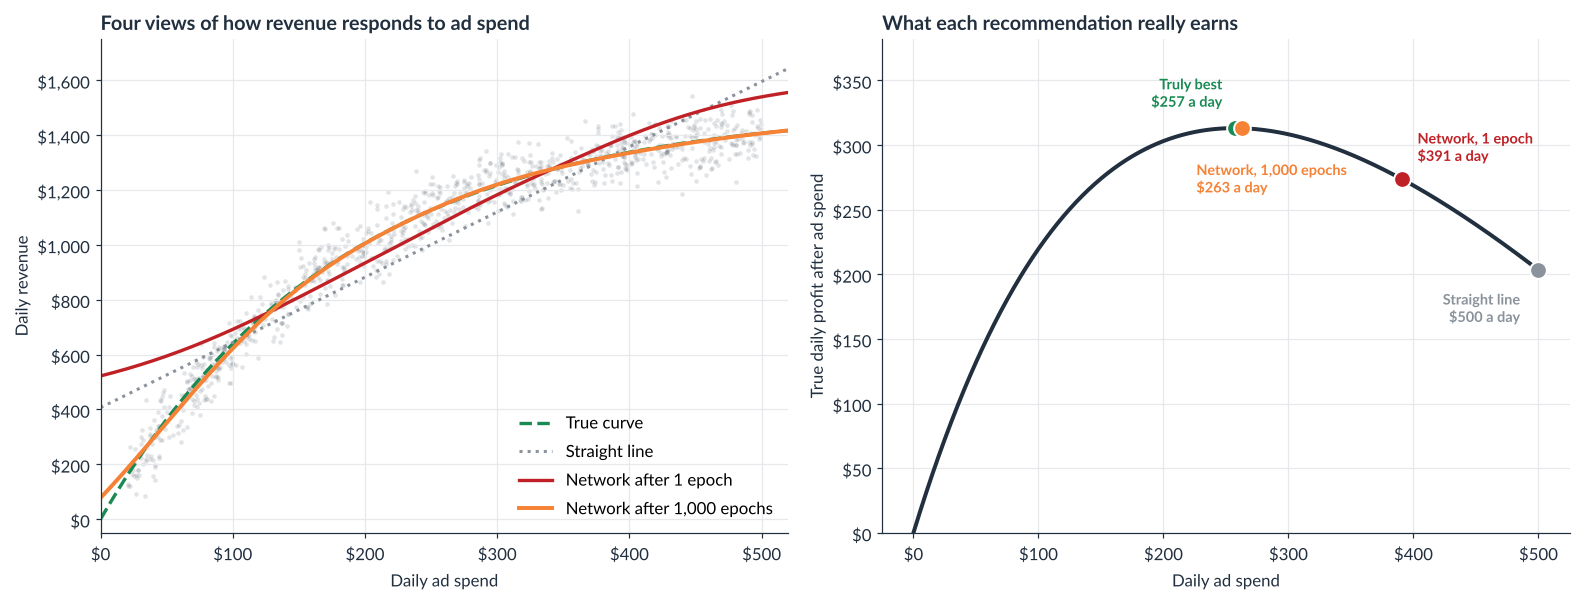

In [26]:
first, last = min(e for e in N["snapshots"] if e > 0), max(N["snapshots"])
name_first = [n for n in budget if f"after {first:,} epoch" in n][0]
name_last = [n for n in budget if f"after {last:,} epoch" in n][0]
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.6))
ax = axes[0]
ax.scatter(spend, revenue, s=9, color=NAVY, alpha=0.13, linewidth=0)
ax.plot(s_grid, true_revenue(s_grid), color=GREEN, lw=2.2, ls="--", label="True curve")
ax.plot(s_grid, line_predict(s_grid), color=GRAY, lw=2, ls=":", label="Straight line")
ax.plot(s_grid, predict_revenue(net_saved[first], s_grid), color=RED, lw=2.2, label=f"Network after {first} epoch")
ax.plot(s_grid, predict_revenue(net_saved[last], s_grid), color=ORANGE, lw=2.6, label=f"Network after {last:,} epochs")
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Daily ad spend"); ax.set_ylabel("Daily revenue")
ax.set_xlim(0, 520); ax.set_ylim(-50, 1750)
ax.legend(loc="lower right")
ax.set_title("Four views of how revenue responds to ad spend")
ax = axes[1]
ax.plot(budget_grid, true_profit(budget_grid), color=NAVY, lw=2.6)
picks = [("Truly best", TRUE_BEST, GREEN, (-8, 14), "right"), (f"Network, {last:,} epochs", budget[name_last], ORANGE, (-30, -42), "left"),
         (f"Network, {first} epoch", budget[name_first], RED, (10, 12), "left"), ("Straight line", budget["Straight line"], GRAY, (-12, -34), "right")]
for label, s, col, off, ha in picks:
    ax.scatter([s], [true_profit(s)], s=120, color=col, edgecolor="white", linewidth=1.3, zorder=5)
    ax.annotate(f"{label}\n${s:,.0f} a day", (s, true_profit(s)), xytext=off, textcoords="offset points",
                fontsize=9.5, color=col, fontweight="bold", ha=ha)
ax.xaxis.set_major_formatter(dollars); ax.yaxis.set_major_formatter(dollars)
ax.set_xlabel("Daily ad spend"); ax.set_ylabel("True daily profit after ad spend")
ax.set_ylim(0, best_profit * 1.22)
ax.set_title("What each recommendation really earns")
fig.tight_layout()
save(fig, "fig13_budget.png")
plt.show()

Start with the straight line. Its slope is the same everywhere, about \$2.38 of revenue per ad dollar, which is above the \$2.00 breakeven. So it says every extra dollar pays, forever, and recommends the largest budget it was shown: \$500 a day. The true curve says returns ran out long before that. Following the line would cost the shop about \$110 a day in profit, around \$40,000 a year. The line was trained perfectly. It's the wrong shape of model, and no amount of gradient descent fixes that.

The network after one pass through the data hasn't learned the bend yet, so it makes a milder version of the same mistake. It recommends \$391 a day and leaves about \$40 a day behind, around \$14,400 a year.

After 10 passes the recommendation is \$289 and the loss is down to a few dollars a day. The fully trained network recommends \$263, within a few percent of the truly best \$257, and gives up almost nothing.

Two honest observations about these results.

**Most of the damage happens early.** The profit curve is flat near its peak, so a budget that's off by \$20 costs pennies. The expensive mistakes came from models that hadn't learned the shape yet. That's good news in practice: you don't need a perfectly trained model, but you do need one that's finished learning the basic shape of the data.

**An unfinished model doesn't look unfinished.** Every row in that table is a confident number in dollars. Nothing about "\$391 a day" says it came from a network that had seen the data once. The only way to know is to ask whether training converged.

The random starts tell a similar story. The ten fully trained networks recommend budgets from \$249 to \$263 a day. They settled into slightly different low spots, and they disagree a little. Here the disagreement costs less than 20 cents a day. On a harder problem it could cost more, which is why "would I get the same answer on a second run?" is a fair question to ask of any model.

## 14. Reference tables

Three tables for the article: the orienteering terms and their machine learning counterparts, where gradient descent shows up in tools marketers use, and a troubleshooting guide.

In [27]:
glossary = pd.DataFrame([
    ["A location on the map", "One choice of the model's settings (parameters, also called weights)"],
    ["Elevation", "Loss: how wrong the model is with those settings"],
    ["Contour line", "Settings that are all equally wrong"],
    ["Slope of the ground", "Derivative (one direction) or gradient (all directions at once)"],
    ["Fall line, straight downhill", "Negative gradient"],
    ["Length of your stride", "Learning rate (step size)"],
    ["Running past the control", "Overshooting: the learning rate is too high"],
    ["Reaching the control", "Convergence: more steps no longer change the answer"],
    ["Lowest point on the map", "Global minimum"],
    ["A depression you can't see out of", "Local minimum"],
    ["Saddle, or a pass between hills", "Saddle point"],
    ["Flat ground", "Plateau: tiny gradients, tiny steps"],
    ["A quick look at the ground nearby", "Stochastic or mini-batch gradient descent"],
    ["Speed carried from running downhill", "Momentum"],
], columns=["On the orienteering course", "In machine learning"])
render_table("table01_orienteering_glossary.png", "From the map to the model",
             "Orienteering terms and their machine learning counterparts", glossary, [34, 58])

tools = pd.DataFrame([
    ["Ad platform bidding", "Models that predict clicks and conversions for each ad auction", "Neural networks trained with stochastic gradient descent, updated as new data arrives"],
    ["Product and content recommendations", "Models that predict what each customer will want next", "Neural networks and matrix factorization, both trained with gradient descent"],
    ["Lookalike and propensity audiences", "Models that score how likely a person is to respond", "Logistic regression at scale, gradient boosting, or neural networks"],
    ["Large language models (chat assistants)", "Models that predict the next word", "Mini-batch stochastic gradient descent with Adam-style step rules"],
    ["Image and video generators", "Models that learn to turn noise into pictures", "The same family of step rules, on very large networks"],
    ["Search, translation, and speech tools", "Models that match meaning across text and audio", "Neural networks trained the same way"],
    ["Where it usually isn't used", "Ordinary linear regression, decision trees, random forests", "A formula gives the answer directly, or the model is built a different way"],
], columns=["Tool", "What's inside", "How it's trained"])
render_table("table04_where_it_shows_up.png", "Where gradient descent shows up in marketing",
             "Tools marketers use every day, and the role gradient descent plays in each", tools, [26, 40, 46])

symptoms = pd.DataFrame([
    ["The loss climbs, bounces, or shows \"nan\"", "The learning rate is too high", "Lower it by a factor of ten"],
    ["The loss barely moves", "The learning rate is too low, or the walk is on a plateau", "Raise the rate, or try momentum or Adam"],
    ["Training stops at the step limit", "The model didn't converge", "Read the warning. Allow more steps or fix the scaling"],
    ["Slow progress in a zigzag", "Inputs are on very different scales", "Standardize the inputs"],
    ["The answer hovers and never settles", "A constant learning rate with stochastic gradient descent", "Add a learning rate schedule"],
    ["A different answer every run", "No random seed was set", "Fix the seed and record it"],
    ["Different quality from different starts", "Local minimums", "Train from several starts and keep the best"],
    ["Training loss keeps falling, new data gets worse", "Overfitting", "Stop earlier, simplify the model, or get more data"],
    ["Well trained, still wrong", "The model is the wrong shape, or the loss measures the wrong thing", "Change the model or the loss. More training won't help"],
], columns=["What you see", "Likely cause", "What to try"])
render_table("table05_troubleshooting.png", "Common ways gradient descent goes wrong",
             "Symptoms, likely causes, and first things to try", symptoms, [36, 40, 40])
symptoms

Saved tables/table01_orienteering_glossary.png and a CSV copy


Saved tables/table04_where_it_shows_up.png and a CSV copy


Saved tables/table05_troubleshooting.png and a CSV copy


,What you see,Likely cause,What to try
0,"The loss climbs, bounces, or shows ""nan""",The learning rate is too high,Lower it by a factor of ten
1,The loss barely moves,"The learning rate is too low, or the walk is o...","Raise the rate, or try momentum or Adam"
2,Training stops at the step limit,The model didn't converge,Read the warning. Allow more steps or fix the ...
3,Slow progress in a zigzag,Inputs are on very different scales,Standardize the inputs
4,The answer hovers and never settles,A constant learning rate with stochastic gradi...,Add a learning rate schedule
5,A different answer every run,No random seed was set,Fix the seed and record it
6,Different quality from different starts,Local minimums,Train from several starts and keep the best
7,"Training loss keeps falling, new data gets worse",Overfitting,"Stop earlier, simplify the model, or get more ..."
8,"Well trained, still wrong","The model is the wrong shape, or the loss meas...",Change the model or the loss. More training wo...


## 15. Checking the results

A check that every result in the notebook does what the text claims. If any check fails, this cell stops with an error. The checks come in two kinds, labeled in the `Type` column.

**Math checks** should pass under any settings. They confirm that:

- Every hand-written gradient (the terrain, the line, and backpropagation for the network) matches the tiny-step estimate from Section 3.
- The gradient crosses the contour lines at right angles.
- The lowest point and the depression are true low points, and the saddle is a true saddle.
- On the simple bowl, each step multiplies the distance from the bottom by (1 - 2 * learning rate).
- Settings converted back to dollars give the same predictions as the scaled versions.
- The truly best budget is where gross margin times the slope of the revenue curve equals 1.

**Simulation results** confirm what these particular simulated examples show, so they can change if you change the settings. They confirm that:

- The walk from start A reaches the lowest point without ever going uphill, the walk from start B gets stuck in the depression, and momentum gets out of it.
- Gradient descent on the line matches the textbook formula.
- Raw dollars hit the step limit, and standardizing takes the fewest steps.
- Mini-batch makes more progress per pass than batch, and a schedule shrinks the spread of single-row SGD.
- The network beats the straight line, lands near scikit-learn's result, and recommends a budget close to the truly best one.
- The under-trained network recommends a worse budget, and the random starts end in slightly different places.

A simulation result shows that the notebook produced the example it describes. It doesn't prove the same thing will happen with every data set.

In [28]:
checks = []
MATH, SIM = "Math", "Simulation result"
def check(name, passed, detail, kind=SIM):
    # Math checks should pass under any settings. Simulation results describe what these
    # particular simulated examples show and can change if you change the settings.
    checks.append({"Type": kind, "Check": name, "Passed": bool(passed), "Detail": detail})

# --- Math checks ---
check("Terrain gradient matches the tiny-step estimate", GRAD_ERR < 1e-4, f"largest difference {GRAD_ERR:.1e} m per km", MATH)
check("Gradient is at right angles to the contours", ALONG_SLOPE < 1e-4, f"slope along the contour at most {ALONG_SLOPE:.1e}", MATH)

def curvature(p, h=1e-4):
    # How the ground curves at p: both numbers positive = a low point, one of each sign = a saddle
    H = np.column_stack([(terrain_gradient(p + e) - terrain_gradient(p - e)) / (2 * h) for e in (np.array([h, 0]), np.array([0, h]))])
    return np.linalg.eigvalsh((H + H.T) / 2)
c_low, c_dep, c_sad = curvature(LOW), curvature(DEP), curvature(SADDLE)
check("Lowest point and depression are true low points", c_low.min() > 0 and c_dep.min() > 0,
      f"curvatures {c_low.round(1)} and {c_dep.round(1)}", MATH)
check("The saddle is a true saddle", c_sad.min() < 0 < c_sad.max() and np.linalg.norm(terrain_gradient(SADDLE)) < 1e-6,
      f"curvatures {c_sad.round(1)}", MATH)
check("The depression is higher than the lowest point", elevation(DEP) > elevation(LOW),
      f"{elevation(DEP):.1f} m vs. {elevation(LOW):.1f} m", MATH)

ok, detail = True, []
for r, path in bowl_runs.items():
    nz = np.abs(path[:-1]) > 1e-12
    ratios = path[1:][nz] / path[:-1][nz]
    ok &= np.allclose(ratios, 1 - 2 * r, atol=1e-9)
    if r > 1:
        ok &= bool(np.all(np.abs(np.diff(np.abs(path))) > 0) and abs(path[-1]) > abs(path[0]))
    detail.append(f"{r}: x{1 - 2 * r:+.2f}")
check("Bowl: each step multiplies the distance by (1 - 2 * rate)", ok, ", ".join(detail), MATH)

check("Line gradient matches the tiny-step estimate", LINE_GRAD_ERR < 1e-6, f"relative difference {LINE_GRAD_ERR:.1e}", MATH)
check(f"Backpropagation matches the tiny-step estimate for all {N_WEIGHTS} weights", BACKPROP_ERR < 1e-6,
      f"largest difference {BACKPROP_ERR:.1e}", MATH)

worst = 0.0
for name, (x, r) in runs.items():
    b = scale_fits[name]["path"][-1]
    i0, per_dollar = to_dollars(name, b)
    worst = max(worst, np.abs((b[0] + b[1] * x) - (i0 + per_dollar * spend)).max())
check("Settings converted back to dollars give the same predictions", worst < 1e-6, f"largest difference ${worst:.1e}", MATH)

mr = C["gross_margin"] * true_revenue_slope(TRUE_BEST)
check("Best budget: gross margin * slope of the revenue curve = 1", abs(mr - 1) < 1e-9, f"{mr:.9f}", MATH)
check("Best budget from the formula matches a direct search", abs(recommend(true_revenue) - TRUE_BEST) <= 1.0,
      f"${recommend(true_revenue):,.0f} vs. ${TRUE_BEST:,.2f}", MATH)

# --- Simulation results ---
d_a = np.linalg.norm(walk_a["path"][-1] - LOW) * 1000
check("Start A reaches the lowest point", walk_a["converged"] and d_a < 1.0, f"{walk_a['steps']} steps, {d_a:.2f} m away")
rises = int((np.diff(walk_a["loss"]) > 1e-12).sum() + (np.diff(walk_b["loss"]) > 1e-12).sum())
check("Elevation never rises at the default learning rate", rises == 0, f"{rises} uphill steps from starts A and B")
d_b = np.linalg.norm(walk_b["path"][-1] - DEP) * 1000
check("Start B gets stuck in the depression", walk_b["converged"] and d_b < 1.0 and walk_b["loss"][-1] > walk_a["loss"][-1] + 1,
      f"{d_b:.2f} m from its floor, {walk_b['loss'][-1] - walk_a['loss'][-1]:.1f} m above the lowest point")
far = np.linalg.norm(rate_walks["Too small"]["path"][-1] - LOW)
check("The too-small learning rate is still far away after the same steps", far > 1.0 and not rate_walks["Too small"]["converged"],
      f"{far:.2f} km away after {G['steps_shown']} steps")
big = rate_walks["Too large"]
turns = int((np.diff(big["loss"]) > 0).sum())
check("The too-large learning rate overshoots", turns > 5, f"elevation went back up on {turns} of {big['steps']} steps")
w_m = opt_walks["Momentum"][0]
check("Momentum escapes the depression from start B", np.linalg.norm(w_m["path"][-1] - LOW) < 0.05,
      f"ended at {w_m['loss'][-1]:.1f} m after {w_m['steps']} steps")

diff = np.abs(b_gd - b_formula).max()
check("Line: gradient descent matches the textbook formula", fit_line["converged"] and diff < 0.01, f"largest difference ${diff:.4f}")
s_raw, s_100, s_std = (scale_fits[k] for k in runs)
check("Raw dollars hit the step limit without converging", not s_raw["converged"] and s_raw["steps"] == G["max_steps"],
      f"{s_raw['steps']:,} steps, rate ${s_raw['path'][-1][1]:.2f} vs. ${b_formula[1] / 100:.2f}")
check("Standardizing takes the fewest steps", s_std["converged"] and s_std["steps"] < s_100["steps"] < s_raw["steps"],
      f"{s_std['steps']} vs. {s_100['steps']} vs. {s_raw['steps']:,}")

e_batch, e_mini, e_one = (np.sqrt(sgd_runs[v[0]]["epoch_loss"][-1]) for v in variants)
check("Mini-batch and single-row make more progress per pass than batch", e_mini < e_batch and e_one < e_batch,
      f"typical miss after {B['epochs']} epochs: ${e_batch:,.0f} batch, ${e_mini:,.2f} mini-batch, ${e_one:,.2f} single-row")
sp_const = seed_results[("Stochastic (1 row)", "Constant learning rate")].std()
sp_sched = seed_results[("Stochastic (1 row)", "With a schedule")].std()
check("A schedule shrinks the spread of single-row SGD", sp_sched < sp_const / 2, f"${sp_const:.2f} down to ${sp_sched:.2f}")
worst_sched = max(np.abs(seed_results[(m, "With a schedule")] / b_formula[1] - 1).max()
                  for m in ["Stochastic (1 row)", "Mini-batch (32 rows)"])
check("With a schedule, every seed lands within 5% of the formula's rate", worst_sched < 0.05, f"farthest {worst_sched:.1%}")

net_rmse = to_rmse(net_history[-1])
check("The network fits better than the straight line", net_rmse < line_rmse, f"${net_rmse:,.2f} vs. ${line_rmse:,.2f}")
check("The network lands near scikit-learn's result", net_rmse < 1.05 * sk_rmse, f"${net_rmse:,.2f} vs. ${sk_rmse:,.2f}")
check("The network can't beat the noise in the data by much", net_rmse > 0.95 * noise_rmse, f"${net_rmse:,.2f} vs. ${noise_rmse:,.2f}")
rec_last, rec_first = budget[name_last], budget[name_first]
check("The trained network's budget is within 10% of the truly best", abs(rec_last / TRUE_BEST - 1) < 0.10,
      f"${rec_last:,.0f} vs. ${TRUE_BEST:,.0f}")
check("The under-trained network's budget is farther off and earns less",
      abs(rec_first - TRUE_BEST) > abs(rec_last - TRUE_BEST) and true_profit(rec_first) < true_profit(rec_last),
      f"${rec_first:,.0f} earning ${true_profit(rec_first):,.2f} vs. ${rec_last:,.0f} earning ${true_profit(rec_last):,.2f}")
check("The straight line recommends the largest budget it was shown", budget["Straight line"] == budget_grid.max(),
      f"${budget['Straight line']:,.0f}")
check("Random starts end at different losses", np.ptp(start_hist[:, -1]) > 0,
      f"typical miss ${final.min():,.2f} to ${final.max():,.2f}")
check("Every random start's budget earns within 2% of the best possible", start_left.max() < 0.02 * best_profit,
      f"at most ${start_left.max():.2f} a day behind")

results = pd.DataFrame(checks)
n_math, n_sim = (results["Type"] == MATH).sum(), (results["Type"] == SIM).sum()
print(f"{results['Passed'].sum()} of {len(results)} checks passed ({n_math} math checks, {n_sim} simulation results)")
if not results["Passed"].all():
    print(results[~results["Passed"]].to_string(index=False))
    raise AssertionError("Some checks failed. See the rows above.")
pd.set_option("display.max_colwidth", 90)
results

31 of 31 checks passed (11 math checks, 20 simulation results)


,Type,Check,Passed,Detail
0,Math,Terrain gradient matches the tiny-step estimate,True,largest difference 1.7e-09 m per km
1,Math,Gradient is at right angles to the contours,True,slope along the contour at most 1.4e-09
2,Math,Lowest point and depression are true low points,True,curvatures [6.1 7.2] and [21.5 30.2]
3,Math,The saddle is a true saddle,True,curvatures [-13.9 11.6]
4,Math,The depression is higher than the lowest point,True,21.1 m vs. 0.2 m
5,Math,Bowl: each step multiplies the distance by (1 - 2 * rate),True,"0.1: x+0.80, 0.5: x+0.00, 0.95: x-0.90, 1.05: x-1.10"
6,Math,Line gradient matches the tiny-step estimate,True,relative difference 8.0e-11
7,Math,Backpropagation matches the tiny-step estimate for all 25 weights,True,largest difference 6.0e-11
8,Math,Settings converted back to dollars give the same predictions,True,largest difference $2.3e-13
9,Math,Best budget: gross margin * slope of the revenue curve = 1,True,1.000000000


## 16. Summary

In [29]:
summary = pd.DataFrame([
    ["Terrain: lowest point vs. depression floor", f"{elevation(LOW):.0f} m vs. {elevation(DEP):.0f} m"],
    ["Terrain: steps from start A to the lowest point", f"{walk_a['steps']} at learning rate {G['terrain_rate']}"],
    ["Terrain: share of starting points that end in the depression", f"{SHARE_STUCK:.0%}"],
    ["Terrain: from start B, plain / momentum / Adam end in",
     " / ".join(where(w["path"][-1]) for w, _ in opt_walks.values())],
    ["Line: revenue per extra ad dollar, gradient descent vs. formula", f"${b_gd[1] / 100:.4f} vs. ${b_formula[1] / 100:.4f}"],
    ["Scaling: steps in raw dollars / hundreds / standardized",
     f"{s_raw['steps']:,} (not converged) / {s_100['steps']} / {s_std['steps']}"],
    [f"SGD: steps taken in {B['epochs']} epochs, batch / mini-batch / single-row",
     " / ".join(f"{sgd_runs[v[0]]['steps']:,}" for v in variants)],
    [f"SGD: typical miss after {B['epochs']} epochs, batch / mini-batch / single-row",
     f"${e_batch:,.0f} / ${e_mini:,.2f} / ${e_one:,.2f}"],
    ["Typical miss: straight line / neural network / noise in the data", f"${line_rmse:,.2f} / ${net_rmse:,.2f} / ${noise_rmse:,.2f}"],
    ["Budget: truly best daily ad spend and profit", f"${TRUE_BEST:,.0f} earning ${best_profit:,.2f} a day"],
    ["Budget: straight line recommends", f"${budget['Straight line']:,.0f}, leaving ${best_profit - true_profit(budget['Straight line']):,.2f} a day behind"],
    [f"Budget: network after {first} epoch recommends", f"${rec_first:,.0f}, leaving ${best_profit - true_profit(rec_first):,.2f} a day behind"],
    [f"Budget: network after {last:,} epochs recommends", f"${rec_last:,.0f}, leaving ${best_profit - true_profit(rec_last):,.2f} a day behind"],
    [f"Budget: range across {N['n_starts']} random starts", f"${start_budgets.min():,.0f} to ${start_budgets.max():,.0f} a day"],
], columns=["Result", "Value"])
render_table("table06_summary.png", "An introduction to gradient descent: key results",
             "Simulated data with illustrative assumptions", summary, [56, 44])
summary

Saved tables/table06_summary.png and a CSV copy


,Result,Value
0,Terrain: lowest point vs. depression floor,0 m vs. 21 m
1,Terrain: steps from start A to the lowest point,86 at learning rate 0.03
2,Terrain: share of starting points that end in the depression,27%
3,"Terrain: from start B, plain / momentum / Adam end in",the depression / the lowest point / the depression
4,"Line: revenue per extra ad dollar, gradient descent vs. formula",$2.3771 vs. $2.3771
5,Scaling: steps in raw dollars / hundreds / standardized,"10,000 (not converged) / 713 / 22"
6,"SGD: steps taken in 50 epochs, batch / mini-batch / single-row","50 / 1,600 / 50,000"
7,"SGD: typical miss after 50 epochs, batch / mini-batch / single-row",$172 / $125.77 / $128.81
8,Typical miss: straight line / neural network / noise in the data,$125.76 / $60.86 / $60.00
9,Budget: truly best daily ad spend and profit,$257 earning $313.12 a day


### Takeaways

1. **Gradient descent is how most machine learning models and nearly all neural networks learn.** Start with a guess, find the slope, step downhill, repeat.
2. **The gradient is a list of slopes, one per setting.** It points straight uphill, so the model steps the other way.
3. **The learning rate decides whether it works.** Too small and training crawls. Too large and it overshoots or blows up.
4. **It can get stuck.** Gradient descent stops wherever the ground is flat, and it can't tell a local minimum from the global one. Where it starts decides where it finishes.
5. **Units matter.** Inputs on very different scales turn the loss surface into a ravine. Standardizing them is cheap and often makes the difference between a model that trains and one that doesn't.
6. **Stochastic gradient descent trades exactness for speed.** Many cheap, noisy steps beat a few expensive, exact ones on large data, at the price of results that depend on the random seed.
7. **Backpropagation computes the gradient, and gradient descent uses it.** That pairing trains everything from the 25-weight network here to a large language model.
8. **An unfinished or stuck model still gives confident answers.** "Did training converge, and would I get the same answer on a second run?" is a business question.

Gradient descent finds the bottom of whatever terrain it's given. It has no opinion about whether that's the right terrain. Choosing the model and the loss is still your job.

### Try it yourself

The numbers in the text describe the default settings. Change a setting and rerun everything to see new results in the code, charts, and tables.

- In the `T` cell, move `start_b` to `(5.0, 9.5)`. Does the walk still get stuck? Try a few more starts and compare with the red and green map in Section 7.
- In the `G` cell, raise `terrain_rate` a little at a time. At what value does the walk from start A stop reaching the lowest point?
- In the `T` cell, deepen the depression by changing its height from -30 to -45. Does momentum still escape?
- In the `G` cell, change `line_rate_raw` from 1e-5 to 2e-5. What happens to the raw-dollar fit, and what does the validation cell say?
- In the `B` cell, set `decay` to 0. What happens to the spread of answers across seeds?
- In the `N` cell, change `hidden_units` to 2, then to 32. How does the fitted curve change, and what happens to the recommended budget?
- In the `C` cell, change `gross_margin` to 0.35. How does the best budget move, and does the straight line still say to spend the maximum?

### Related articles

- [Objective Functions for Marketers: How Models Decide What "Best" Means](https://blog.marketingdatascience.ai/objective-functions-for-marketers-how-models-decide-what-best-means-b737f1705d6b)
- [Loss Functions for Marketers: How Models Decide What "Wrong" Means](https://blog.marketingdatascience.ai/loss-functions-for-marketers-how-models-decide-what-wrong-means-1e66a55bc825)
- [An Introduction to Linear Algebra: The Math I Slept Through in College That Now Powers AI](https://blog.marketingdatascience.ai/an-introduction-to-linear-algebra-the-math-i-slept-through-in-college-that-now-powers-ai-c4831f688496)
- [A Marketer's Guide to Calculus](https://blog.marketingdatascience.ai/a-marketers-guide-to-calculus-9ced95758447)
- [Marketing with Neural Networks: What They Are and How to Use Them](https://blog.marketingdatascience.ai/marketing-with-neural-networks-what-they-are-and-how-to-use-them-3e0114771c40)
- [Neural Networks Explained from First Principles in R](https://blog.marketingdatascience.ai/neural-networks-explained-from-first-principles-in-r-795bc158cf37)
- [Linear Regression: The Classic Machine Learning Algorithm You Need to Know](https://blog.marketingdatascience.ai/linear-regression-the-classic-machine-learning-algorithm-you-need-to-know-1fe0b48b06a3)
- [Is Your Marketing Model Too Accurate?](https://blog.marketingdatascience.ai/is-your-marketing-model-too-accurate-5076f5163326)
- [Business Lessons from the Sport of Orienteering](https://thecitizen.com/2023/04/11/business-lessons-from-the-sport-of-orienteering/)

All data in this notebook is simulated. Nothing here comes from a real business.

## Optional: the same network in PyTorch

Everything above was written out by hand so you could see each step. In practice, people use a library such as PyTorch, where backpropagation is one line (`loss.backward()`) and the gradient descent step is another (`optimizer.step()`). The step rule is something you pick by name: `SGD` or `Adam`.

The cell below trains the same 25-weight network both ways. PyTorch comes preinstalled in Google Colab. If it isn't installed where you're running this, the cell skips itself. It isn't part of the checks above.

In [30]:
try:
    import torch
except ImportError:
    torch = None
    print("PyTorch isn't installed here, so this optional cell was skipped.")

if torch is not None:
    X_t = torch.tensor(xs, dtype=torch.float32).reshape(-1, 1)
    Y_t = torch.tensor(ys, dtype=torch.float32).reshape(-1, 1)
    TORCH_EPOCHS = 200
    step_rules = {"SGD": lambda params: torch.optim.SGD(params, lr=N["rate"]),
                  "Adam": lambda params: torch.optim.Adam(params, lr=N["rate"])}
    for name, make_optimizer in step_rules.items():
        torch.manual_seed(SEED)
        model = torch.nn.Sequential(torch.nn.Linear(1, N["hidden_units"]), torch.nn.Tanh(),
                                    torch.nn.Linear(N["hidden_units"], 1))
        optimizer = make_optimizer(model.parameters())
        batches = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(X_t, Y_t),
                                              batch_size=N["batch_size"], shuffle=True)
        for epoch in range(TORCH_EPOCHS):
            for x_batch, y_batch in batches:
                optimizer.zero_grad()                                        # clear the old gradient
                loss = torch.nn.functional.mse_loss(model(x_batch), y_batch) # forward pass
                loss.backward()                                              # backpropagation
                optimizer.step()                                             # the gradient descent step
        with torch.no_grad():
            mse = torch.nn.functional.mse_loss(model(X_t), Y_t).item()
        print(f"PyTorch with {name:4s}: typical miss ${to_rmse(mse):,.2f} after {TORCH_EPOCHS} epochs "
              f"(hand-written network: ${to_rmse(net_history[TORCH_EPOCHS]):,.2f} at {TORCH_EPOCHS} epochs, "
              f"${to_rmse(net_history[-1]):,.2f} at {N['epochs']:,})")

PyTorch with SGD : typical miss $62.09 after 200 epochs (hand-written network: $63.05 at 200 epochs, $60.86 at 1,000)


PyTorch with Adam: typical miss $60.87 after 200 epochs (hand-written network: $63.05 at 200 epochs, $60.86 at 1,000)
